# Factor Dispersion and Active-Risk Budgeting: Evidence from Factor Momentum

## Replication analysis

This single-file notebook generates the empirical exhibits and portfolio strategies reported in *Factor Dispersion and Active-Risk Budgeting: Evidence from Factor Momentum*. It includes matched 4% tracking-error budgets with and without FDI scaling, equally sampled raw-dispersion comparisons, predictive regressions, gross/net portfolio results, subperiods, BAB exclusions, paired Sharpe intervals and the original exhibit figures. All datasets reside directly in one local folder.

In [1]:
from pathlib import Path
DATA_DIR = Path(r"PATH of DATA")  # EDIT ONLY THIS LINE


## Research design and implementation safeguards

Seven monthly U.S. factor sleeves are standardized by lagged 36-month volatility. FDI states use expanding percentiles after 60 valid observations. Momentum ranks use the latest 12-month compounded factor returns relative to lagged 36-month volatility. End-month decisions trade next-month outcomes. All portfolios have a 10% annual ex-ante total-volatility target, a leverage cap of 2.0, and an illustrative cost of 10 basis points per unit of one-way turnover. The two matched tracking-error strategies target 4% ex-ante TE and cap active tilt at 1.25 times the regular momentum tilt: one uses no state multiplier, and the other adjusts the predicted risk by 0.80 (low FDI), 1.00 (middle) or 1.25 (high), reducing the tilt in high states. No additional data location or parent directory setting is required.

In [2]:
from __future__ import annotations

import json
import math
import warnings
from io import BytesIO
from pathlib import Path
from typing import Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


warnings.filterwarnings("ignore", category=RuntimeWarning)

FACTOR_NAMES = ["MKT", "SMB", "HML", "RMW", "CMA", "MOM", "BAB"]
VOL_WINDOW = 36
MOM_WINDOW = 12
MIN_FDI_HISTORY = 60
TILT_STRENGTH = 0.75
TARGET_VOL = 0.10
MAX_LEVERAGE = 2.0
TRANSACTION_COST_BPS = 10.0


def _find_file(data_dir: Path, required_tokens: Iterable[str]) -> Path:
    tokens = [token.lower() for token in required_tokens]
    for path in sorted(data_dir.iterdir()):
        name = path.name.lower()
        if all(token in name for token in tokens):
            return path
    raise FileNotFoundError(
        f"Could not locate a file containing {tokens} in {data_dir.resolve()}"
    )


def _month_end_from_yyyymm(values: pd.Series) -> pd.DatetimeIndex:
    parsed = pd.to_datetime(values.astype(str).str.strip(), format="%Y%m")
    return pd.DatetimeIndex(parsed + pd.offsets.MonthEnd(0))


def load_input_data(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    ff5_path = _find_file(data_dir, ["research", "5", "factor"])
    mom_path = _find_file(data_dir, ["momentum", "monthly"])
    bab_path = _find_file(data_dir, ["bab"])
    vix_path = _find_file(data_dir, ["vix"])

    ff5 = pd.read_csv(ff5_path)
    ff5.index = _month_end_from_yyyymm(ff5["Date"])
    ff5 = ff5.rename(columns={"Mkt-RF": "MKT"})[
        ["MKT", "SMB", "HML", "RMW", "CMA", "RF"]
    ].apply(pd.to_numeric, errors="coerce") / 100.0

    mom = pd.read_csv(mom_path)
    mom.index = _month_end_from_yyyymm(mom["Date"])
    mom = mom[["MOM"]].apply(pd.to_numeric, errors="coerce") / 100.0

    bab_bytes = bab_path.read_bytes()
    if bab_bytes[:2] == b"PK":
        bab = pd.read_excel(BytesIO(bab_bytes))
    else:
        bab = pd.read_csv(BytesIO(bab_bytes))
    bab.columns = [str(c).strip().upper() for c in bab.columns]
    date_col = next(c for c in bab.columns if "DATE" in c)
    value_col = next(c for c in bab.columns if c != date_col and "BAB" in c)
    bab.index = pd.to_datetime(bab[date_col], errors="coerce") + pd.offsets.MonthEnd(0)
    bab = bab[[value_col]].rename(columns={value_col: "BAB"})
    # AQR BAB input may contain strings such as "4.20%"; convert percent to decimal.
    bab_values = bab["BAB"].astype(str).str.strip()
    percent_values = bab_values.str.contains("%", regex=False)
    if percent_values.any() and not percent_values.all():
        raise ValueError("BAB column mixes percent strings and plain decimals; standardize its units first.")
    if percent_values.all():
        bab["BAB"] = pd.to_numeric(bab_values.str.replace("%", "", regex=False), errors="coerce") / 100.0
    else:
        bab["BAB"] = pd.to_numeric(bab_values, errors="coerce")

    factors = ff5.join(mom, how="inner").join(bab, how="inner")
    factors = factors[FACTOR_NAMES + ["RF"]].dropna().sort_index()
    if factors.empty:
        raise ValueError("No overlapping monthly factor observations. Check date alignment and return units, especially the BAB file.")
    if factors.index.has_duplicates:
        raise ValueError("Duplicate monthly factor dates detected; clean inputs before running.")

    vix = pd.read_csv(vix_path)
    vix["date"] = pd.to_datetime(vix["date"], errors="coerce")
    vix["VIX"] = pd.to_numeric(vix["VIX"], errors="coerce")
    vix = vix.dropna(subset=["date"]).set_index("date").sort_index()
    vix_monthly = pd.DataFrame(
        {
            "VIX Average": vix["VIX"].resample("ME").mean(),
            "VIX End": vix["VIX"].resample("ME").last(),
        }
    )
    vix_monthly["VIX Change"] = vix_monthly["VIX End"].diff()

    meta = {
        "factor_start": factors.index.min().strftime("%Y-%m-%d"),
        "factor_end": factors.index.max().strftime("%Y-%m-%d"),
        "factor_observations": int(len(factors)),
        "vix_start": vix_monthly["VIX Average"].dropna().index.min().strftime("%Y-%m-%d"),
        "vix_end": vix_monthly["VIX Average"].dropna().index.max().strftime("%Y-%m-%d"),
        "sources": {
            "ff5": ff5_path.name,
            "momentum": mom_path.name,
            "bab": bab_path.name,
            "vix": vix_path.name,
        },
    }
    return factors, vix_monthly, meta


def max_drawdown(returns: pd.Series | np.ndarray) -> float:
    r = pd.Series(returns).dropna().astype(float)
    if r.empty:
        return np.nan
    wealth = pd.concat([pd.Series([1.0]), (1.0 + r).cumprod()], ignore_index=True)
    return float((wealth / wealth.cummax() - 1.0).min())


def factor_summary(factors: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for factor in FACTOR_NAMES:
        r = factors[factor].dropna()
        ann_return = r.mean() * 12.0
        ann_vol = r.std(ddof=1) * math.sqrt(12.0)
        rows.append(
            {
                "Factor": factor,
                "Annual Return": ann_return,
                "Annual Volatility": ann_vol,
                "Sharpe Ratio": ann_return / ann_vol,
                "Skewness": stats.skew(r, bias=False),
                "Worst Month": r.min(),
                "Maximum Drawdown": max_drawdown(r),
                "Start": r.index.min(),
                "End": r.index.max(),
                "Months": len(r),
            }
        )
    return pd.DataFrame(rows).set_index("Factor")


def expanding_percentile(series: pd.Series, min_history: int = MIN_FDI_HISTORY) -> pd.Series:
    out = pd.Series(index=series.index, dtype=float)
    for i, (date, value) in enumerate(series.items()):
        history = series.iloc[: i + 1].dropna()
        if pd.notna(value) and len(history) >= min_history:
            out.loc[date] = float((history <= value).mean())
    return out


def cross_sectional_rank_signal(scores: pd.DataFrame) -> pd.DataFrame:
    ranks = scores.rank(axis=1, method="average")
    center = (len(scores.columns) + 1.0) / 2.0
    scale = (len(scores.columns) - 1.0) / 2.0
    return (ranks - center) / scale


def construct_fdi(factors: pd.DataFrame, vol_window: int = VOL_WINDOW) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    r = factors[FACTOR_NAMES]
    ex_ante_vol = r.rolling(vol_window, min_periods=vol_window).std(ddof=1).shift(1)
    standardized = r / ex_ante_vol
    signals = pd.DataFrame(index=r.index)
    signals["FDI"] = standardized.std(axis=1, ddof=1)
    signals["Mean Standardized Return"] = standardized.mean(axis=1)
    signals["Absolute Mean Standardized Return"] = standardized.mean(axis=1).abs()
    signals["Standardized Range"] = standardized.max(axis=1) - standardized.min(axis=1)
    signals["Positive Factor Share"] = (standardized > 0).mean(axis=1)
    signals["Average Ex-Ante Factor Volatility"] = ex_ante_vol.mean(axis=1) * math.sqrt(12.0)
    signals["FDI Percentile"] = expanding_percentile(signals["FDI"])
    signals["FDI State"] = pd.cut(
        signals["FDI Percentile"],
        bins=[-np.inf, 1.0 / 3.0, 2.0 / 3.0, np.inf],
        labels=["Low", "Middle", "High"],
        right=False,
    ).astype(object)
    signals["Opportunity Strength"] = signals["FDI State"].map(
        {"Low": 0.0, "Middle": 0.5, "High": 1.0}
    )
    return signals, standardized, ex_ante_vol


def momentum_scores(factors: pd.DataFrame, vol_window: int = VOL_WINDOW, mom_window: int = MOM_WINDOW) -> pd.DataFrame:
    r = factors[FACTOR_NAMES]
    trailing_return = (1.0 + r).rolling(mom_window, min_periods=mom_window).apply(np.prod, raw=True) - 1.0
    current_vol = r.rolling(vol_window, min_periods=vol_window).std(ddof=1) * math.sqrt(12.0)
    return trailing_return / current_vol


def normalize_rows(weights: pd.DataFrame) -> pd.DataFrame:
    return weights.div(weights.sum(axis=1), axis=0)


def ex_ante_scale_weights(
    raw_weights: pd.DataFrame,
    returns: pd.DataFrame,
    vol_window: int = VOL_WINDOW,
    target_vol: float = TARGET_VOL,
    max_leverage: float = MAX_LEVERAGE,
) -> tuple[pd.DataFrame, pd.Series]:
    scaled = pd.DataFrame(index=raw_weights.index, columns=raw_weights.columns, dtype=float)
    expected_vol = pd.Series(index=raw_weights.index, dtype=float)
    for date in raw_weights.index:
        pos = returns.index.get_loc(date)
        if pos < vol_window - 1:
            continue
        sample = returns.iloc[pos - vol_window + 1 : pos + 1][raw_weights.columns]
        if len(sample) < vol_window or sample.isna().any().any():
            continue
        cov = sample.cov().to_numpy(dtype=float) * 12.0
        w = raw_weights.loc[date].to_numpy(dtype=float)
        vol = math.sqrt(max(float(w @ cov @ w), 0.0))
        leverage = min(max_leverage, target_vol / vol) if vol > 0 else np.nan
        scaled.loc[date] = w * leverage
        expected_vol.loc[date] = vol * leverage
    return scaled, expected_vol


def build_decision_weights(
    factors: pd.DataFrame,
    signals: pd.DataFrame,
    vol_window: int = VOL_WINDOW,
    mom_window: int = MOM_WINDOW,
    tilt_strength: float = TILT_STRENGTH,
) -> tuple[dict[str, pd.DataFrame], pd.DataFrame, pd.DataFrame]:
    r = factors[FACTOR_NAMES]
    current_vol = r.rolling(vol_window, min_periods=vol_window).std(ddof=1)
    base = normalize_rows(1.0 / current_vol)
    scores = momentum_scores(factors, vol_window, mom_window)
    rank_signal = cross_sectional_rank_signal(scores)
    opportunity = signals["Opportunity Strength"].reindex(r.index)

    raw = {
        "Risk-Balanced": base,
        "Momentum Tilt": normalize_rows(base * (1.0 + tilt_strength * rank_signal)),
        "Reversal Tilt": normalize_rows(base * (1.0 - tilt_strength * rank_signal)),
        "FDI-Aware Momentum": normalize_rows(
            base * (1.0 + tilt_strength * rank_signal.mul(opportunity, axis=0))
        ),
        "FDI-Aware Reversal": normalize_rows(
            base * (1.0 - tilt_strength * rank_signal.mul(opportunity, axis=0))
        ),
    }

    # Forward-looking active-risk forecasts use trailing covariance available at t.
    # FDI-state multipliers are fixed before evaluating subsequent returns.
    # A separate capped tilt targets a 4% tracking-error budget, relative to the
    # risk-balanced baseline; it is not an optimized timing schedule.
    te_scale = {"Low": 0.80, "Middle": 1.00, "High": 1.25}
    adjusted = pd.DataFrame(index=r.index, columns=r.columns, dtype=float)
    constant_te = pd.DataFrame(index=r.index, columns=r.columns, dtype=float)
    te_forecast = pd.Series(index=r.index, dtype=float)
    te_target = 0.04
    for date in r.index:
        state = signals.at[date, "FDI State"]
        pos = r.index.get_loc(date)
        if state not in te_scale or pos < vol_window - 1:
            continue
        block = r.iloc[pos - vol_window + 1:pos + 1]
        if block.isna().any().any():
            continue
        change = raw["Momentum Tilt"].loc[date] - base.loc[date]
        covariance = block.cov().to_numpy() * 12
        risk = math.sqrt(max(float(change.to_numpy() @ covariance @ change.to_numpy()), 0.0))
        expected = risk * te_scale[state]
        te_forecast.loc[date] = expected
        intensity = min(1.25, te_target / max(expected, 1e-6))
        adjusted.loc[date] = base.loc[date] + intensity * change
        constant_intensity = min(1.25, te_target / max(risk, 1e-6))
        constant_te.loc[date] = base.loc[date] + constant_intensity * change
    raw["FDI-Informed TE Budget"] = adjusted
    raw["Constant TE Budget"] = constant_te

    scaled = {}
    for name, w in raw.items():
        scaled[name], _ = ex_ante_scale_weights(w, r, vol_window)
    return scaled, scores, rank_signal


def strategy_returns_from_decisions(
    factors: pd.DataFrame,
    decision_weights: dict[str, pd.DataFrame],
    transaction_cost_bps: float = TRANSACTION_COST_BPS,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, pd.DataFrame]]:
    r = factors[FACTOR_NAMES]
    gross = pd.DataFrame(index=r.index)
    net = pd.DataFrame(index=r.index)
    turnover = pd.DataFrame(index=r.index)
    held_weights = {}
    for name, decisions in decision_weights.items():
        held = decisions.shift(1)
        held_weights[name] = held
        gross[name] = (held * r).sum(axis=1, min_count=1)
        one_way_turnover = 0.5 * held.diff().abs().sum(axis=1, min_count=1)
        initial = 0.5 * held.abs().sum(axis=1, min_count=1)
        first_valid = held.dropna(how="all").index.min()
        if pd.notna(first_valid):
            one_way_turnover.loc[first_valid] = initial.loc[first_valid]
        turnover[name] = one_way_turnover
        net[name] = gross[name] - (transaction_cost_bps / 10000.0) * one_way_turnover
    return gross, net, turnover, held_weights


def strategy_performance(returns: pd.DataFrame, turnover: pd.DataFrame) -> pd.DataFrame:
    rows = []
    common_start = returns.dropna(how="any").index.min()
    aligned = returns.loc[common_start:].dropna(how="any")
    for name in aligned.columns:
        r = aligned[name]
        ann_return = r.mean() * 12.0
        ann_vol = r.std(ddof=1) * math.sqrt(12.0)
        downside = np.minimum(r.to_numpy(), 0.0)
        rows.append(
            {
                "Strategy": name,
                "Annual Return": ann_return,
                "Annual Volatility": ann_vol,
                "Sharpe Ratio": ann_return / ann_vol,
                "Downside Deviation": math.sqrt(np.mean(downside**2) * 12.0),
                "Maximum Drawdown": max_drawdown(r),
                "Worst Month": r.min(),
                "Average One-Way Turnover": turnover.loc[r.index, name].mean(),
                "Start": r.index.min(),
                "End": r.index.max(),
                "Months": len(r),
            }
        )
    return pd.DataFrame(rows).set_index("Strategy")


def state_opportunity_table(
    factors: pd.DataFrame,
    signals: pd.DataFrame,
    standardized: pd.DataFrame,
    scores: pd.DataFrame,
    rank_signal: pd.DataFrame,
    gross_returns: pd.DataFrame,
) -> pd.DataFrame:
    next_standardized = standardized.shift(-1)
    next_dispersion = next_standardized.std(axis=1, ddof=1)
    next_range = next_standardized.max(axis=1) - next_standardized.min(axis=1)
    next_raw = factors[FACTOR_NAMES].shift(-1)
    invvol = 1.0 / factors[FACTOR_NAMES].rolling(VOL_WINDOW).std(ddof=1)
    spread_w = rank_signal * invvol
    spread_w = spread_w.div(spread_w.abs().sum(axis=1), axis=0) * 2.0
    momentum_spread = (spread_w * next_raw).sum(axis=1, min_count=1)
    reversal_spread = -momentum_spread

    frame = pd.DataFrame(
        {
            "FDI": signals["FDI"],
            "FDI State": signals["FDI State"],
            "Next-Month FDI": signals["FDI"].shift(-1),
            "Next-Month Standardized Dispersion": next_dispersion,
            "Next-Month Standardized Range": next_range,
            "Momentum Selection Spread": momentum_spread,
            "Reversal Selection Spread": reversal_spread,
            "Risk-Balanced Next Return": gross_returns["Risk-Balanced"].shift(-1),
        }
    ).dropna(subset=["FDI State", "Next-Month FDI", "Momentum Selection Spread"])
    rows = []
    for state in ["Low", "Middle", "High"]:
        s = frame[frame["FDI State"] == state]
        rows.append(
            {
                "FDI State": state,
                "Months": len(s),
                "Current FDI": s["FDI"].mean(),
                "Next-Month FDI": s["Next-Month FDI"].mean(),
                "Next-Month Standardized Range": s["Next-Month Standardized Range"].mean(),
                "Momentum Selection Spread (Annualized)": s["Momentum Selection Spread"].mean() * 12.0,
                "Momentum Spread t-Statistic": s["Momentum Selection Spread"].mean() / (s["Momentum Selection Spread"].std(ddof=1) / math.sqrt(len(s))),
                "Reversal Selection Spread (Annualized)": s["Reversal Selection Spread"].mean() * 12.0,
                "Risk-Balanced Return (Annualized)": s["Risk-Balanced Next Return"].mean() * 12.0,
            }
        )
    return pd.DataFrame(rows).set_index("FDI State")


def active_payoff_by_state(
    signals: pd.DataFrame,
    gross_returns: pd.DataFrame,
    net_returns: pd.DataFrame,
) -> pd.DataFrame:
    state_for_return = signals["FDI State"].shift(1)
    rows = []
    benchmark = gross_returns["Risk-Balanced"]
    benchmark_net = net_returns["Risk-Balanced"]
    for state in ["Low", "Middle", "High"]:
        mask = state_for_return == state
        for strategy in ["Momentum Tilt", "Reversal Tilt", "FDI-Aware Momentum", "FDI-Aware Reversal"]:
            g = (gross_returns[strategy] - benchmark)[mask].dropna()
            n = (net_returns[strategy] - benchmark_net)[mask].dropna()
            rows.append(
                {
                    "FDI State": state,
                    "Strategy": strategy,
                    "Months": len(g),
                    "Gross Active Return": g.mean() * 12.0,
                    "Gross Active t-Statistic": g.mean() / (g.std(ddof=1) / math.sqrt(len(g))) if len(g) > 1 and g.std(ddof=1) > 0 else np.nan,
                    "Net Active Return": n.mean() * 12.0,
                    "Active Volatility": n.std(ddof=1) * math.sqrt(12.0),
                    "Information Ratio": n.mean() / n.std(ddof=1) * math.sqrt(12.0) if n.std(ddof=1) > 0 else np.nan,
                }
            )
    return pd.DataFrame(rows).set_index(["FDI State", "Strategy"])


def newey_west_regression(y: pd.Series, x: pd.DataFrame, lags: int = 3) -> dict:
    frame = pd.concat([y.rename("y"), x], axis=1).dropna()
    yv = frame["y"].to_numpy(dtype=float)
    xv0 = frame.drop(columns="y")
    names = ["Intercept"] + list(xv0.columns)
    xv = np.column_stack([np.ones(len(frame)), xv0.to_numpy(dtype=float)])
    xtx_inv = np.linalg.pinv(xv.T @ xv)
    beta = xtx_inv @ xv.T @ yv
    resid = yv - xv @ beta
    meat = np.zeros((xv.shape[1], xv.shape[1]))
    for t in range(len(frame)):
        xt = xv[t : t + 1].T
        meat += resid[t] ** 2 * (xt @ xt.T)
    for lag in range(1, min(lags, len(frame) - 1) + 1):
        weight = 1.0 - lag / (lags + 1.0)
        gamma = np.zeros_like(meat)
        for t in range(lag, len(frame)):
            xt = xv[t : t + 1].T
            xl = xv[t - lag : t - lag + 1].T
            gamma += resid[t] * resid[t - lag] * (xt @ xl.T)
        meat += weight * (gamma + gamma.T)
    cov = xtx_inv @ meat @ xtx_inv
    se = np.sqrt(np.maximum(np.diag(cov), 0.0))
    tstats = np.divide(beta, se, out=np.full_like(beta, np.nan), where=se > 0)
    fitted = xv @ beta
    sst = np.sum((yv - yv.mean()) ** 2)
    return {
        "n": len(frame),
        "r2": 1.0 - np.sum((yv - fitted) ** 2) / sst if sst > 0 else np.nan,
        "coef": dict(zip(names, beta)),
        "tstat": dict(zip(names, tstats)),
    }


def predictive_regressions(signals: pd.DataFrame, vix: pd.DataFrame) -> pd.DataFrame:
    frame = signals.join(vix[["VIX Average", "VIX Change"]], how="left")
    frame["Next FDI"] = frame["FDI"].shift(-1)
    frame["Next Standardized Range"] = frame["Standardized Range"].shift(-1)
    fdi_z = (frame["FDI"] - frame["FDI"].mean()) / frame["FDI"].std(ddof=1)
    frame["FDI z"] = fdi_z
    frame["Average Vol z"] = (
        frame["Average Ex-Ante Factor Volatility"] - frame["Average Ex-Ante Factor Volatility"].mean()
    ) / frame["Average Ex-Ante Factor Volatility"].std(ddof=1)
    specs = [
        ("Next-month FDI", "Next FDI", ["FDI z"], 3),
        ("Next-month standardized range", "Next Standardized Range", ["FDI z"], 3),
        ("Next-month range, controlling for factor volatility", "Next Standardized Range", ["FDI z", "Average Vol z"], 3),
        ("Next-month range, VIX sample", "Next Standardized Range", ["FDI z", "Average Vol z", "VIX Average"], 3),
    ]
    rows = []
    for label, ycol, xcols, lags in specs:
        reg = newey_west_regression(frame[ycol], frame[xcols], lags)
        row = {"Specification": label, "Observations": reg["n"], "R-squared": reg["r2"]}
        for x in xcols:
            row[f"{x} Coefficient"] = reg["coef"][x]
            row[f"{x} t-Statistic"] = reg["tstat"][x]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Specification")


def factor_continuation_by_state(
    factors: pd.DataFrame,
    signals: pd.DataFrame,
    scores: pd.DataFrame,
) -> pd.DataFrame:
    next_r = factors[FACTOR_NAMES].shift(-1)
    ranks = scores.rank(axis=1, method="average")
    rows = []
    for state in ["Low", "Middle", "High"]:
        mask = signals["FDI State"] == state
        for factor in FACTOR_NAMES:
            top = mask & (ranks[factor] >= 6)
            bottom = mask & (ranks[factor] <= 2)
            top_return = next_r.loc[top, factor].mean() * 12.0
            bottom_return = next_r.loc[bottom, factor].mean() * 12.0
            rows.append(
                {
                    "FDI State": state,
                    "Factor": factor,
                    "Top-Rank Months": int(top.sum()),
                    "Top-Rank Next Return": top_return,
                    "Bottom-Rank Months": int(bottom.sum()),
                    "Bottom-Rank Next Return": bottom_return,
                    "Continuation Spread": top_return - bottom_return,
                }
            )
    return pd.DataFrame(rows).set_index(["FDI State", "Factor"])


def robustness_table(
    factors: pd.DataFrame,
    vix: pd.DataFrame,
    output_root: Path | None = None,
) -> pd.DataFrame:
    rows = []
    specifications = [
        (24, 6, 0.75),
        (24, 12, 0.75),
        (36, 6, 0.75),
        (36, 12, 0.50),
        (36, 12, 0.75),
        (36, 12, 1.00),
        (60, 12, 0.75),
        (36, 18, 0.75),
    ]
    for vol_window, mom_window, tilt in specifications:
        sig, std, _ = construct_fdi(factors, vol_window)
        weights, scores, rank_signal = build_decision_weights(
            factors, sig, vol_window, mom_window, tilt
        )
        gross, net, turnover, _ = strategy_returns_from_decisions(factors, weights)
        perf = strategy_performance(net, turnover)
        active = active_payoff_by_state(sig, gross, net)
        high_mom = active.loc[("High", "FDI-Aware Momentum")]
        high_rev = active.loc[("High", "FDI-Aware Reversal")]
        rows.append(
            {
                "Volatility Window": vol_window,
                "Momentum Window": mom_window,
                "Tilt Strength": tilt,
                "Momentum Tilt Return": perf.loc["Momentum Tilt", "Annual Return"],
                "Momentum Tilt Sharpe": perf.loc["Momentum Tilt", "Sharpe Ratio"],
                "FDI-Aware Momentum Return": perf.loc["FDI-Aware Momentum", "Annual Return"],
                "FDI-Aware Momentum Sharpe": perf.loc["FDI-Aware Momentum", "Sharpe Ratio"],
                "FDI-Aware Momentum Max Drawdown": perf.loc["FDI-Aware Momentum", "Maximum Drawdown"],
                "High-FDI Momentum Active Return": high_mom["Net Active Return"],
                "FDI-Aware Reversal Return": perf.loc["FDI-Aware Reversal", "Annual Return"],
                "FDI-Aware Reversal Sharpe": perf.loc["FDI-Aware Reversal", "Sharpe Ratio"],
                "High-FDI Reversal Active Return": high_rev["Net Active Return"],
                "Benchmark Sharpe": perf.loc["Risk-Balanced", "Sharpe Ratio"],
            }
        )
    return pd.DataFrame(rows)


def subperiod_performance(net_returns: pd.DataFrame, turnover: pd.DataFrame) -> pd.DataFrame:
    periods = [
        ("1971-1989", "1971-01-01", "1989-12-31"),
        ("1990-2006", "1990-01-01", "2006-12-31"),
        ("2007-2026", "2007-01-01", "2026-12-31"),
    ]
    rows = []
    for label, start, end in periods:
        r = net_returns.loc[start:end]
        t = turnover.loc[r.index]
        perf = strategy_performance(r, t)
        for strategy in ["Risk-Balanced", "Momentum Tilt", "FDI-Aware Momentum", "FDI-Aware Reversal"]:
            row = perf.loc[strategy]
            rows.append(
                {
                    "Subperiod": label,
                    "Strategy": strategy,
                    "Annual Return": row["Annual Return"],
                    "Annual Volatility": row["Annual Volatility"],
                    "Sharpe Ratio": row["Sharpe Ratio"],
                    "Maximum Drawdown": row["Maximum Drawdown"],
                    "Months": row["Months"],
                }
            )
    return pd.DataFrame(rows).set_index(["Subperiod", "Strategy"])


def make_figures(
    output_dir: Path,
    signals: pd.DataFrame,
    vix: pd.DataFrame,
    active: pd.DataFrame,
    net_returns: pd.DataFrame,
) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titlesize": 11,
        "axes.labelsize": 9,
        "legend.fontsize": 8,
    })

    s = signals.dropna(subset=["FDI"])
    fig, ax = plt.subplots(figsize=(9.6, 5.2))
    ax.plot(s.index, s["FDI"], color="black", linewidth=1.25)
    ax.axhline(s["FDI"].median(), color="0.45", linestyle="--", linewidth=0.9, label="Full-sample median")
    ax.fill_between(s.index, s["FDI"], s["FDI"].median(), where=s["FDI"] >= s["FDI"].median(), color="0.85", alpha=0.8)
    ax.set_title("EXHIBIT 3, PANEL A  Factor Dispersion Index")
    ax.set_ylabel("Cross-sectional standard deviation")
    ax.grid(axis="y", color="0.88", linewidth=0.6)
    ax.legend(frameon=False, loc="upper right")
    fig.text(0.08, 0.025, "Sample: July 1966-March 2026. FDI uses factor returns standardized by lagged 36-month volatility.", fontsize=8)
    fig.tight_layout(rect=(0.04, 0.07, 0.98, 0.96))
    fig.savefig(output_dir / "Exhibit_3_Panel_A_Factor_Dispersion_Index.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    joint = signals[["FDI"]].join(vix[["VIX Average"]], how="inner").dropna()
    fig, ax1 = plt.subplots(figsize=(9.6, 5.2))
    ax1.plot(joint.index, joint["FDI"], color="black", linewidth=1.2, label="FDI")
    ax1.set_ylabel("FDI")
    ax2 = ax1.twinx()
    ax2.plot(joint.index, joint["VIX Average"], color="0.5", linewidth=0.9, linestyle="--", label="VIX")
    ax2.set_ylabel("Monthly average VIX")
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [line.get_label() for line in lines], frameon=False, loc="upper right")
    ax1.set_title("EXHIBIT 3, PANEL B  FDI and Market Stress")
    ax1.grid(axis="y", color="0.88", linewidth=0.6)
    corr = joint.corr().iloc[0, 1]
    fig.text(0.08, 0.025, f"Sample: January 1990-March 2026. Contemporaneous correlation = {corr:.2f}.", fontsize=8)
    fig.tight_layout(rect=(0.04, 0.07, 0.98, 0.96))
    fig.savefig(output_dir / "Exhibit_3_Panel_B_FDI_and_VIX.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    plot_rows = []
    for state in ["Low", "Middle", "High"]:
        for strategy in ["Momentum Tilt", "Reversal Tilt"]:
            plot_rows.append((state, strategy, active.loc[(state, strategy), "Net Active Return"]))
    plot = pd.DataFrame(plot_rows, columns=["State", "Strategy", "Return"])
    states = ["Low", "Middle", "High"]
    x = np.arange(len(states))
    width = 0.34
    fig, ax = plt.subplots(figsize=(8.7, 5.1))
    mom = [plot[(plot.State == st) & (plot.Strategy == "Momentum Tilt")].Return.iloc[0] * 100 for st in states]
    rev = [plot[(plot.State == st) & (plot.Strategy == "Reversal Tilt")].Return.iloc[0] * 100 for st in states]
    ax.bar(x - width / 2, mom, width, color="0.2", label="Momentum tilt")
    ax.bar(x + width / 2, rev, width, color="0.75", edgecolor="0.25", hatch="//", label="Reversal tilt")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, states)
    ax.set_ylabel("Annualized net active return (%)")
    ax.set_title("EXHIBIT 6  Directional Payoffs across FDI States")
    ax.legend(frameon=False)
    ax.grid(axis="y", color="0.88", linewidth=0.6)
    fig.text(0.08, 0.02, "Active return is measured relative to the risk-balanced benchmark; 10 bps per unit of one-way turnover.", fontsize=8)
    fig.tight_layout(rect=(0.04, 0.07, 0.98, 0.96))
    fig.savefig(output_dir / "Exhibit_6_Directional_Payoffs_by_FDI_State.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    common = net_returns[["Risk-Balanced", "Momentum Tilt", "FDI-Aware Momentum", "FDI-Aware Reversal"]].dropna()
    wealth = (1.0 + common).cumprod()
    fig, ax = plt.subplots(figsize=(9.6, 5.2))
    styles = {
        "Risk-Balanced": ("black", "-"),
        "Momentum Tilt": ("0.35", "--"),
        "FDI-Aware Momentum": ("0.6", "-."),
        "FDI-Aware Reversal": ("0.15", ":"),
    }
    for name in wealth.columns:
        color, ls = styles[name]
        ax.plot(wealth.index, wealth[name], color=color, linestyle=ls, linewidth=1.25, label=name)
    ax.set_yscale("log")
    ax.set_ylabel("Growth of $1 (log scale)")
    ax.set_title("EXHIBIT 9, PANEL A  Cumulative Wealth")
    ax.legend(frameon=False, ncol=2)
    ax.grid(axis="y", color="0.88", linewidth=0.6)
    fig.text(0.08, 0.02, "Net hypothetical returns; 10% ex-ante volatility target, 2.0 leverage cap, and 10 bps per unit of one-way turnover.", fontsize=8)
    fig.tight_layout(rect=(0.04, 0.07, 0.98, 0.96))
    fig.savefig(output_dir / "Exhibit_9_Panel_A_Cumulative_Wealth.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    dd = wealth.div(wealth.cummax()).sub(1.0)
    fig, ax = plt.subplots(figsize=(9.6, 5.2))
    for name in dd.columns:
        color, ls = styles[name]
        ax.plot(dd.index, dd[name] * 100, color=color, linestyle=ls, linewidth=1.15, label=name)
    ax.set_ylabel("Drawdown (%)")
    ax.set_title("EXHIBIT 9, PANEL B  Drawdowns")
    ax.legend(frameon=False, ncol=2, loc="lower left")
    ax.grid(axis="y", color="0.88", linewidth=0.6)
    fig.text(0.08, 0.02, "Drawdowns are calculated from the net hypothetical wealth paths in Panel A.", fontsize=8)
    fig.tight_layout(rect=(0.04, 0.07, 0.98, 0.96))
    fig.savefig(output_dir / "Exhibit_9_Panel_B_Drawdowns.png", dpi=300, bbox_inches="tight")
    plt.close(fig)


def save_tables(output_dir: Path, tables: dict[str, pd.DataFrame]) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    for name, table in tables.items():
        table.to_csv(output_dir / f"{name}.csv")


def dataframe_payload(table: pd.DataFrame) -> dict:
    df = table.reset_index()
    flat_columns = []
    for col in df.columns:
        if isinstance(col, tuple):
            parts = [str(part) for part in col if str(part) not in ("", "None")]
            flat_columns.append(" — ".join(parts))
        else:
            flat_columns.append(str(col))
    df.columns = flat_columns
    rows = []
    for row in df.itertuples(index=False, name=None):
        converted = []
        for value in row:
            if isinstance(value, (pd.Timestamp, np.datetime64)):
                converted.append(pd.Timestamp(value).strftime("%Y-%m-%d"))
            elif pd.isna(value):
                converted.append(None)
            elif isinstance(value, (np.integer,)):
                converted.append(int(value))
            elif isinstance(value, (np.floating,)):
                converted.append(float(value))
            else:
                converted.append(value)
        rows.append(converted)
    return {"columns": flat_columns, "rows": rows}


def extended_analyses(factors, signals, scores, rank_signal, gross, net, turnover):
    """Compact practitioner tests; all predictors are observable at month-end t."""
    r = factors[FACTOR_NAMES]
    now = signals.copy()
    now["Raw Dispersion"] = r.std(axis=1, ddof=1)
    # 6-month trailing realized total-volatility proxy including month t.
    now["Short Realized Vol"] = r.rolling(6, min_periods=6).std().mean(axis=1) * math.sqrt(12)
    # Contemporary volatility surprise: absolute returns relative to slow ex-ante estimates.
    slow = r.rolling(36, min_periods=36).std().shift(1)
    now["Short/Slow Vol Ratio"] = (r.rolling(6, min_periods=6).std() / slow).mean(axis=1)
    now["Next Range"] = now["Standardized Range"].shift(-1)
    now["Next Raw Range"] = r.max(axis=1).sub(r.min(axis=1)).shift(-1)
    now["Next FDI"] = now["FDI"].shift(-1)
    for col in ["FDI", "Raw Dispersion", "Short Realized Vol", "Short/Slow Vol Ratio", "Average Ex-Ante Factor Volatility"]:
        now[col + " z"] = (now[col] - now[col].mean()) / now[col].std(ddof=1)
    regressions = [
        ("FDI + 6m volatility", "Next Range", ["FDI z", "Short Realized Vol z"]),
        ("FDI + volatility surprise", "Next Range", ["FDI z", "Short/Slow Vol Ratio z"]),
        ("FDI + raw dispersion", "Next Range", ["FDI z", "Raw Dispersion z"]),
        ("Raw dispersion only", "Next Range", ["Raw Dispersion z"]),
        ("FDI + raw dispersion + short vol", "Next Range", ["FDI z", "Raw Dispersion z", "Short Realized Vol z"]),
        ("FDI on next raw range", "Next Raw Range", ["FDI z"]),
        ("Raw dispersion on next raw range", "Next Raw Range", ["Raw Dispersion z"]),
    ]
    rows=[]
    for name,y,x in regressions:
        # Raw-range comparisons use the same FDI-eligible dates.
        y_data = now[y].where(now["FDI z"].notna()) if (y == "Next Raw Range" or name == "Raw dispersion only") else now[y]
        fit=newey_west_regression(y_data,now[x])
        rec={"Specification":name,"Observations":fit["n"],"R-squared":fit["r2"]}
        for k in x:
            rec[k+" Coefficient"]=fit["coef"][k]
            rec[k+" t-Statistic"]=fit["tstat"][k]
        rows.append(rec)
    predictive_extra=pd.DataFrame(rows).set_index("Specification")

    # The diagnostic spread is identical to the original Exhibit 4 methodology.
    invvol=1/r.rolling(VOL_WINDOW).std(ddof=1)
    weight=rank_signal * invvol
    weight=weight.div(weight.abs().sum(axis=1), axis=0) * 2
    spread=(weight*r.shift(-1)).sum(axis=1,min_count=1)
    tests={
        "Signed spread on FDI percentile":(spread,signals[["FDI Percentile"]]),
        "Absolute spread on FDI percentile":(spread.abs(),signals[["FDI Percentile"]]),
    }
    results=[]
    for name,(y,x) in tests.items():
        reg=newey_west_regression(y,x)
        results.append({"Test":name,"Months":reg["n"],"FDI percentile slope":reg["coef"]["FDI Percentile"],"Newey-West t":reg["tstat"]["FDI Percentile"],"R-squared":reg["r2"]})
    # Difference in next-month spread means, high vs low, with NW inference.
    state=signals["FDI State"]
    selector=state.isin(["Low","High"])
    dummy=(state=="High").astype(float).rename("High minus low")
    reg=newey_west_regression(spread.where(selector),dummy.to_frame())
    results.append({"Test":"High-minus-low momentum spread (monthly)","Months":reg["n"],"FDI percentile slope":reg["coef"]["High minus low"],"Newey-West t":reg["tstat"]["High minus low"],"R-squared":reg["r2"]})
    slope_table=pd.DataFrame(results).set_index("Test")

    # Paired 12-month moving-block bootstrap for Sharpe differences.
    common=net[["Risk-Balanced","Momentum Tilt","FDI-Aware Momentum","FDI-Informed TE Budget","Constant TE Budget"]].dropna()
    values=common.to_numpy()
    rng=np.random.default_rng(20261011)
    block_length=12
    repeats=1500
    estimates=[]
    n=len(values)
    for _ in range(repeats):
        sample=[]
        while len(sample)<n:
            start=int(rng.integers(0,n-block_length+1))
            sample.extend(range(start,start+block_length))
        z=values[np.asarray(sample[:n])]
        sharpe=z.mean(axis=0)/z.std(axis=0,ddof=1)*math.sqrt(12)
        estimates.append([sharpe[1]-sharpe[0],sharpe[2]-sharpe[0],sharpe[2]-sharpe[1],sharpe[3]-sharpe[1],sharpe[3]-sharpe[4]])
    bootstrap=pd.DataFrame(estimates,columns=["Momentum - benchmark","FDI gate - benchmark","FDI gate - momentum","FDI TE budget - momentum","FDI TE budget - constant TE budget"])
    point=common.mean()/common.std(ddof=1)*math.sqrt(12)
    diffs=[point.iloc[1]-point.iloc[0],point.iloc[2]-point.iloc[0],point.iloc[2]-point.iloc[1],point.iloc[3]-point.iloc[1],point.iloc[3]-point.iloc[4]]
    sharpes=pd.DataFrame({"Difference":diffs,"Bootstrap 2.5%":bootstrap.quantile(.025).to_numpy(),"Bootstrap 97.5%":bootstrap.quantile(.975).to_numpy(),"Bootstrap two-sided p":2*np.minimum((bootstrap<=0).mean(),(bootstrap>=0).mean())},index=bootstrap.columns)

    # Trailing active-portfolio TE compared with FDI as a predictor of absolute
    # next-month net active outcome; not a calibrated future TE estimate.
    act=net["Momentum Tilt"]-net["Risk-Balanced"]
    trail_te=act.rolling(12,min_periods=12).std(ddof=1)*math.sqrt(12)
    abs_next=act.shift(-1).abs()
    tey=(abs_next).rename("Next absolute active return")
    tex=pd.DataFrame({"FDI percentile":signals["FDI Percentile"],"Trailing active TE":trail_te})
    te_rows=[]
    # Freeze the identical 657 decision months for all three specifications.
    common_te = pd.concat([tey, tex], axis=1).dropna()
    for label,xx in [("FDI only",["FDI percentile"]),("Trailing TE only",["Trailing active TE"]),("FDI and trailing TE",["FDI percentile","Trailing active TE"])]:
        reg=newey_west_regression(common_te["Next absolute active return"],common_te[xx]);row={"Specification":label,"N":reg["n"],"R-squared":reg["r2"]}
        for v in xx:row[v+" Coef"]=reg["coef"][v];row[v+" t"]=reg["tstat"][v]
        te_rows.append(row)
    te_comparison=pd.DataFrame(te_rows).set_index("Specification")
    return predictive_extra,slope_table,sharpes,te_comparison


def without_bab_test(factors):
    global FACTOR_NAMES
    existing=FACTOR_NAMES.copy()
    try:
        FACTOR_NAMES=[x for x in existing if x != "BAB"]
        six=factors.drop(columns=["BAB"])
        sig,_,_=construct_fdi(six)
        decision,_,_=build_decision_weights(six,sig)
        gross,net,turn,_=strategy_returns_from_decisions(six,decision)
        gross_perf=strategy_performance(gross,turn)
        net_perf=strategy_performance(net,turn)
        return gross_perf,net_perf,sig
    finally:
        FACTOR_NAMES=existing


def run_analysis(data_dir: Path, output_dir: Path) -> dict:
    output_dir.mkdir(parents=True, exist_ok=True)
    tables_dir = output_dir / "tables"
    figures_dir = output_dir / "figures"

    factors, vix, meta = load_input_data(data_dir)
    signals, standardized, ex_ante_vol = construct_fdi(factors)
    decision_weights, scores, rank_signal = build_decision_weights(factors, signals)
    gross, net, turnover, held_weights = strategy_returns_from_decisions(factors, decision_weights)

    summary = factor_summary(factors)
    fdi_summary = pd.DataFrame(
        {
            "Statistic": ["Mean", "Median", "Std. Dev.", "5th Percentile", "95th Percentile", "Minimum", "Maximum", "Lag-1 Autocorrelation"],
            "FDI": [
                signals["FDI"].mean(), signals["FDI"].median(), signals["FDI"].std(ddof=1),
                signals["FDI"].quantile(0.05), signals["FDI"].quantile(0.95),
                signals["FDI"].min(), signals["FDI"].max(), signals["FDI"].autocorr(1),
            ],
        }
    ).set_index("Statistic")
    state_opportunity = state_opportunity_table(factors, signals, standardized, scores, rank_signal, gross)
    predictive = predictive_regressions(signals, vix)
    active = active_payoff_by_state(signals, gross, net)
    continuation = factor_continuation_by_state(factors, signals, scores)
    performance_gross = strategy_performance(gross, turnover)
    performance_net = strategy_performance(net, turnover)
    predictive_extra, slope_tests, sharpe_intervals, te_comparison = extended_analyses(factors,signals,scores,rank_signal,gross,net,turnover)
    no_bab_gross,no_bab_net,no_bab_signals=without_bab_test(factors)
    robustness = robustness_table(factors, vix)
    subperiods = subperiod_performance(net, turnover)
    # Maintain identical three periods for both TE-targeted comparisons.
    te_subperiods=[]
    boundaries=[("1971-1989","1971-07-01","1989-12-31"),("1990-2006","1990-01-01","2006-12-31"),("2007-2026","2007-01-01","2026-03-31")]
    for label,start,end in boundaries:
        for strategy in ["FDI-Informed TE Budget","Constant TE Budget"]:
            z=net.loc[start:end,strategy].dropna()
            if z.empty:continue
            te_subperiods.append({"Subperiod":label,"Strategy":strategy,"Annual Return":z.mean()*12,
                "Annual Volatility":z.std(ddof=1)*math.sqrt(12),"Sharpe Ratio":z.mean()/z.std(ddof=1)*math.sqrt(12),
                "Maximum Drawdown":max_drawdown(z),"Months":len(z)})
    subperiods=pd.concat([subperiods.reset_index(),pd.DataFrame(te_subperiods)],ignore_index=True).set_index(["Subperiod","Strategy"])
    sequence=["Risk-Balanced","Momentum Tilt","FDI-Aware Momentum","FDI-Informed TE Budget","Constant TE Budget","FDI-Aware Reversal"]
    index=pd.MultiIndex.from_product([[x[0] for x in boundaries],sequence],names=["Subperiod","Strategy"])
    subperiods=subperiods.reindex(index)

    # Fixed, illustrative sleeve-turnover charges; these are not underlying trading costs.
    cost_rows = []
    for cost_bps in [0.0, 10.0, 25.0]:
        cost_net = gross - (cost_bps / 10000.0) * turnover
        cost_perf = strategy_performance(cost_net, turnover)
        for strategy in ["Risk-Balanced", "Momentum Tilt", "FDI-Aware Momentum"]:
            cost_rows.append({
                "Cost (bps per one-way sleeve turnover)": cost_bps,
                "Strategy": strategy,
                "Annual Return": cost_perf.loc[strategy, "Annual Return"],
                "Sharpe Ratio": cost_perf.loc[strategy, "Sharpe Ratio"],
            })
    cost_sensitivity = pd.DataFrame(cost_rows).set_index(
        ["Cost (bps per one-way sleeve turnover)", "Strategy"]
    )

    rules = pd.DataFrame(
        [
            ["Risk-Balanced", "Inverse lagged 36-month volatility", "None", "Monthly", "10%", "2.0"],
            ["Momentum Tilt", "Risk-balanced", "Overweight high 12-month risk-adjusted ranks", "Monthly", "10%", "2.0"],
            ["Reversal Tilt", "Risk-balanced", "Overweight low 12-month risk-adjusted ranks", "Monthly", "10%", "2.0"],
            ["FDI-Aware Momentum", "Risk-balanced", "Momentum tilt strength 0/0.5/1 in low/middle/high FDI", "Monthly", "10%", "2.0"],
            ["FDI-Aware Reversal", "Risk-balanced", "Reversal tilt strength 0/0.5/1 in low/middle/high FDI", "Monthly", "10%", "2.0"],
            ["FDI-Informed TE Budget", "Risk-balanced", "4% TE target, 1.25x cap; high-state forecast multiplied by 1.25, shrinking tilt", "Monthly", "10%", "2.0"],
            ["Constant TE Budget", "Risk-balanced", "Same 4% TE target and 1.25x cap; risk multiplier fixed at 1.00 for every FDI state", "Monthly", "10%", "2.0"],
        ],
        columns=["Strategy", "Strategic Anchor", "Active Rule", "Rebalancing", "Volatility Target", "Leverage Cap"],
    ).set_index("Strategy")

    fdi_ts = signals.join(vix, how="left")
    strategy_wealth = (1.0 + net.dropna(how="any")).cumprod()
    strategy_drawdown = strategy_wealth.div(strategy_wealth.cummax()).sub(1.0)
    strategy_series = pd.concat(
        {"Net Return": net, "Wealth": strategy_wealth, "Drawdown": strategy_drawdown}, axis=1
    )

    tables = {
        "Exhibit_1_Factor_Characteristics": summary,
        "Exhibit_2_FDI_Construction_Summary": fdi_summary,
        "Exhibit_2_Standardized_Return_Correlation": standardized.corr(),
        "Exhibit_3_Time_Series_Data": fdi_ts,
        "Exhibit_4_State_Opportunity": state_opportunity,
        "Exhibit_5_Predictive_Regressions": predictive,
        "Exhibit_5_Incremental_Controls": predictive_extra,
        "Exhibit_5_Trailing_TE_Comparison": te_comparison,
        "Exhibit_4_Spread_Predictive_Tests": slope_tests,
        "Exhibit_8_Sharpe_Difference_Bootstrap": sharpe_intervals,
        "Exhibit_10_Excluding_BAB": no_bab_net,
        "Exhibit_10_Excluding_BAB_Gross": no_bab_gross,
        "Exhibit_6_Active_Payoff_by_State": active,
        "Exhibit_7_Factor_Continuation_by_State": continuation,
        "Exhibit_8_Allocation_Rules": rules,
        "Exhibit_8_Gross_Performance": performance_gross,
        "Exhibit_8_Net_Performance": performance_net,
        "Exhibit_9_Strategy_Time_Series": strategy_series,
        "Exhibit_10_Robustness": robustness,
        "Exhibit_10_Subperiods": subperiods,
        "Exhibit_10_Cost_Sensitivity": cost_sensitivity,
    }
    save_tables(tables_dir, tables)
    make_figures(figures_dir, signals, vix, active, net)
    payload = {name: dataframe_payload(table) for name, table in tables.items()}
    (output_dir / "exhibit_payload.json").write_text(
        json.dumps(payload, indent=2, default=str), encoding="utf-8"
    )

    factors.join(signals).to_csv(output_dir / "merged_factor_fdi_data.csv")
    standardized.to_csv(output_dir / "standardized_factor_returns.csv")
    scores.to_csv(output_dir / "factor_momentum_scores.csv")
    gross.to_csv(output_dir / "strategy_gross_returns.csv")
    net.to_csv(output_dir / "strategy_net_returns.csv")
    turnover.to_csv(output_dir / "strategy_turnover.csv")
    for name, weights in held_weights.items():
        safe = name.lower().replace("-", "_").replace(" ", "_")
        weights.to_csv(output_dir / f"weights_{safe}.csv")

    joint_vix = signals[["FDI"]].join(vix[["VIX Average"]], how="inner").dropna()
    key_results = {
        "meta": meta,
        "parameters": {
            "volatility_window_months": VOL_WINDOW,
            "momentum_window_months": MOM_WINDOW,
            "minimum_fdi_history_months": MIN_FDI_HISTORY,
            "tilt_strength": TILT_STRENGTH,
            "target_volatility": TARGET_VOL,
            "maximum_leverage": MAX_LEVERAGE,
            "transaction_cost_bps": TRANSACTION_COST_BPS,
        },
        "fdi": {
            "start": signals["FDI"].dropna().index.min().strftime("%Y-%m-%d"),
            "end": signals["FDI"].dropna().index.max().strftime("%Y-%m-%d"),
            "observations": int(signals["FDI"].notna().sum()),
            "mean": float(signals["FDI"].mean()),
            "median": float(signals["FDI"].median()),
            "autocorrelation": float(signals["FDI"].autocorr(1)),
            "vix_correlation": float(joint_vix.corr().iloc[0, 1]),
        },
        "performance_net": performance_net.reset_index().to_dict(orient="records"),
        "cost_sensitivity": cost_sensitivity.reset_index().to_dict(orient="records"),
        "state_opportunity": state_opportunity.reset_index().to_dict(orient="records"),
        "active_payoff": active.reset_index().to_dict(orient="records"),
        "incremental_controls": predictive_extra.reset_index().to_dict(orient="records"),
        "spread_tests": slope_tests.reset_index().to_dict(orient="records"),
        "sharpe_bootstrap": sharpe_intervals.reset_index().rename(columns={"index":"Comparison"}).to_dict(orient="records"),
        "no_bab_net": no_bab_net.reset_index().to_dict(orient="records"),
    }
    (output_dir / "key_results.json").write_text(json.dumps(key_results, indent=2, default=str), encoding="utf-8")
    return {
        "factors": factors,
        "signals": signals,
        "standardized": standardized,
        "scores": scores,
        "gross": gross,
        "net": net,
        "turnover": turnover,
        "tables": tables,
        "key_results": key_results,
    }


## Run the complete analysis


In [3]:
OUTPUT_DIR = DATA_DIR / "fdi_notebook_outputs"
results = run_analysis(DATA_DIR, OUTPUT_DIR)
print(f"Results written to: {OUTPUT_DIR.resolve()}")
print(f"Factor sample: {results['key_results']['meta']['factor_start']} to {results['key_results']['meta']['factor_end']}")
print(f"Factor observations: {results['key_results']['meta']['factor_observations']}")


Results written to: C:\Users\HP16-af0022TU (D)\Desktop\3JPM\2factor dispersion\new version\fdi_notebook_outputs
Factor sample: 1963-07-31 to 2026-03-31
Factor observations: 753


## Factor-dispersion predictions and independent selection diagnostics


In [4]:
from IPython.display import display
for name in ["Exhibit_2_FDI_Construction_Summary", "Exhibit_4_State_Opportunity", "Exhibit_4_Spread_Predictive_Tests", "Exhibit_5_Predictive_Regressions", "Exhibit_5_Incremental_Controls", "Exhibit_5_Trailing_TE_Comparison"]:
    print("\n" + name.replace("_", " "))
    display(results["tables"][name].round(4))



Exhibit 2 FDI Construction Summary


,FDI
Statistic,
Mean,0.9971
Median,0.8750
Std. Dev.,0.5400
5th Percentile,0.3830
95th Percentile,2.0264
Minimum,0.1597
Maximum,4.5347
Lag-1 Autocorrelation,0.3327



Exhibit 4 State Opportunity


,Months,Current FDI,Next-Month FDI,Next-Month Standardized Range,Momentum Selection Spread (Annualized),Momentum Spread t-Statistic,Reversal Selection Spread (Annualized),Risk-Balanced Return (Annualized)
FDI State,,,,,,,,
Low,234,0.5315,0.7902,2.2058,0.0836,4.1182,-0.0836,0.0873
Middle,210,0.8921,0.9743,2.6898,0.0424,1.5529,-0.0424,0.0892
High,213,1.5773,1.2127,3.3592,0.0924,2.2990,-0.0924,0.0860



Exhibit 4 Spread Predictive Tests


...

,Observations,R-squared,FDI z Coefficient,FDI z t-Statistic,Average Vol z Coefficient,Average Vol z t-Statistic,VIX Average Coefficient,VIX Average t-Statistic
Specification,,,,,,,,
Next-month FDI,716,0.1107,0.1796,8.4949,NaN,NaN,NaN,NaN
Next-month standardized range,716,0.1104,0.4864,8.0422,NaN,NaN,NaN,NaN
"Next-month range, controlling for factor volatility",716,0.1432,0.4238,6.5025,-0.2727,-5.1714,NaN,NaN
"Next-month range, VIX sample",434,0.2577,0.2411,2.2418,-0.4251,-6.3787,0.074,5.8603



Exhibit 5 Incremental Controls


,Observations,R-squared,FDI z Coefficient,FDI z t-Statistic,Short Realized Vol z Coefficient,Short Realized Vol z t-Statistic,Short/Slow Vol Ratio z Coefficient,Short/Slow Vol Ratio z t-Statistic,Raw Dispersion z Coefficient,Raw Dispersion z t-Statistic
Specification,,,,,,,,,,
FDI + 6m volatility,716,0.1105,0.4802,7.6536,0.0204,0.3811,NaN,NaN,NaN,NaN
FDI + volatility surprise,716,0.1552,0.2472,3.1593,NaN,NaN,0.3915,5.2121,NaN,NaN
FDI + raw dispersion,716,0.1204,0.6880,7.4926,NaN,NaN,NaN,NaN,-0.2471,-3.1396
Raw dispersion only,716,0.0441,NaN,NaN,NaN,NaN,NaN,NaN,0.3052,4.7968
FDI + raw dispersion + short vol,716,0.1304,0.7950,7.9704,0.2009,2.8477,NaN,NaN,-0.4526,-4.5029
FDI on next raw range,716,0.0705,0.0130,5.0518,NaN,NaN,NaN,NaN,NaN,NaN
Raw dispersion on next raw range,716,0.1592,NaN,NaN,NaN,NaN,NaN,NaN,0.0194,9.5624



Exhibit 5 Trailing TE Comparison


,N,R-squared,FDI percentile Coef,FDI percentile t,Trailing active TE Coef,Trailing active TE t
Specification,,,,,,
FDI only,657,0.0575,0.0093,3.6529,NaN,NaN
Trailing TE only,657,0.1505,NaN,NaN,0.1467,3.5468
FDI and trailing TE,657,0.1764,0.0063,3.7495,0.1334,3.5193


## Matched TE budgets, Sharpe intervals, BAB exclusion, and subperiod comparisons

In [5]:
for name in ["Exhibit_8_Gross_Performance", "Exhibit_8_Net_Performance", "Exhibit_8_Sharpe_Difference_Bootstrap", "Exhibit_10_Subperiods", "Exhibit_10_Robustness", "Exhibit_10_Excluding_BAB", "Exhibit_10_Cost_Sensitivity"]:
    print("\n" + name.replace("_", " "))
    display(results["tables"][name].round(4))



Exhibit 8 Gross Performance


,Annual Return,Annual Volatility,Sharpe Ratio,Downside Deviation,Maximum Drawdown,Worst Month,Average One-Way Turnover,Start,End,Months
Strategy,,,,,,,,,,
Risk-Balanced,0.0875,0.0745,1.1749,0.0428,-0.2920,-0.1093,0.0222,1971-07-31,2026-03-31,657
Momentum Tilt,0.1165,0.0874,1.3338,0.0496,-0.1711,-0.1047,0.1518,1971-07-31,2026-03-31,657
Reversal Tilt,0.0561,0.0809,0.6939,0.0539,-0.4544,-0.1382,0.1558,1971-07-31,2026-03-31,657
FDI-Aware Momentum,0.1026,0.0823,1.2460,0.0474,-0.1844,-0.1093,0.1851,1971-07-31,2026-03-31,657
FDI-Aware Reversal,0.0712,0.0807,0.8825,0.0525,-0.4335,-0.1382,0.1881,1971-07-31,2026-03-31,657
FDI-Informed TE Budget,0.1228,0.0915,1.3425,0.0520,-0.1735,-0.1112,0.1864,1971-07-31,2026-03-31,657
Constant TE Budget,0.1228,0.0926,1.3267,0.0526,-0.1735,-0.1112,0.1854,1971-07-31,2026-03-31,657



Exhibit 8 Net Performance


,Annual Return,Annual Volatility,Sharpe Ratio,Downside Deviation,Maximum Drawdown,Worst Month,Average One-Way Turnover,Start,End,Months
Strategy,,,,,,,,,,
Risk-Balanced,0.0872,0.0745,1.1714,0.0428,-0.2923,-0.1094,0.0222,1971-07-31,2026-03-31,657
Momentum Tilt,0.1147,0.0874,1.3131,0.0497,-0.1721,-0.1049,0.1518,1971-07-31,2026-03-31,657
Reversal Tilt,0.0543,0.0809,0.6710,0.0541,-0.4557,-0.1383,0.1558,1971-07-31,2026-03-31,657
FDI-Aware Momentum,0.1004,0.0823,1.2192,0.0477,-0.1889,-0.1096,0.1851,1971-07-31,2026-03-31,657
FDI-Aware Reversal,0.0690,0.0807,0.8544,0.0528,-0.4351,-0.1383,0.1881,1971-07-31,2026-03-31,657
FDI-Informed TE Budget,0.1206,0.0915,1.3181,0.0523,-0.1757,-0.1114,0.1864,1971-07-31,2026-03-31,657
Constant TE Budget,0.1206,0.0926,1.3028,0.0528,-0.1757,-0.1114,0.1854,1971-07-31,2026-03-31,657



Exhibit 8 Sharpe Difference Bootstrap


...

,Volatility Window,Momentum Window,Tilt Strength,Momentum Tilt Return,Momentum Tilt Sharpe,FDI-Aware Momentum Return,FDI-Aware Momentum Sharpe,FDI-Aware Momentum Max Drawdown,High-FDI Momentum Active Return,FDI-Aware Reversal Return,FDI-Aware Reversal Sharpe,High-FDI Reversal Active Return,Benchmark Sharpe
0,24,6,0.75,0.1092,1.2693,0.0963,1.2002,-0.2105,0.0169,0.0671,0.8524,-0.0312,1.1555
1,24,12,0.75,0.1110,1.2676,0.0975,1.2023,-0.1947,0.0223,0.0675,0.8561,-0.0342,1.1555
2,36,6,0.75,0.1105,1.2941,0.0987,1.2133,-0.2107,0.0258,0.0692,0.8693,-0.0365,1.1714
3,36,12,0.50,0.1058,1.3218,0.0959,1.2407,-0.1846,0.0219,0.0751,0.9605,-0.0264,1.1714
4,36,12,0.75,0.1147,1.3131,0.1004,1.2192,-0.1889,0.0333,0.0690,0.8544,-0.0394,1.1714
5,36,12,1.00,0.1213,1.2664,0.1047,1.1742,-0.1972,0.0442,0.0626,0.7467,-0.0532,1.1714
6,60,12,0.75,0.1129,1.2361,0.0998,1.1578,-0.1988,0.0276,0.0679,0.7974,-0.0368,1.1126
7,36,18,0.75,0.1054,1.2268,0.0978,1.2045,-0.1902,0.0278,0.0713,0.8943,-0.0341,1.1714



Exhibit 10 Excluding BAB


,Annual Return,Annual Volatility,Sharpe Ratio,Downside Deviation,Maximum Drawdown,Worst Month,Average One-Way Turnover,Start,End,Months
Strategy,,,,,,,,,,
Risk-Balanced,0.0747,0.0700,1.0675,0.0398,-0.1986,-0.0994,0.0211,1971-07-31,2026-03-31,657
Momentum Tilt,0.0955,0.0866,1.1029,0.0486,-0.1783,-0.1014,0.1610,1971-07-31,2026-03-31,657
Reversal Tilt,0.0459,0.0808,0.5676,0.0542,-0.4063,-0.1472,0.1638,1971-07-31,2026-03-31,657
FDI-Aware Momentum,0.0841,0.0807,1.0423,0.0466,-0.1998,-0.1014,0.2045,1971-07-31,2026-03-31,657
FDI-Aware Reversal,0.0581,0.0785,0.7403,0.0511,-0.3880,-0.1472,0.2084,1971-07-31,2026-03-31,657
FDI-Informed TE Budget,0.1005,0.0905,1.1100,0.0509,-0.1793,-0.1129,0.1980,1971-07-31,2026-03-31,657
Constant TE Budget,0.1011,0.0923,1.0961,0.0517,-0.1793,-0.1129,0.1963,1971-07-31,2026-03-31,657



Exhibit 10 Cost Sensitivity


Annual Return  \
Cost (bps per one-way sleeve turnover) Strategy                            
0.0                                    Risk-Balanced              0.0875   
                                       Momentum Tilt              0.1165   
                                       FDI-Aware Momentum         0.1026   
10.0                                   Risk-Balanced              0.0872   
                                       Momentum Tilt              0.1147   
                                       FDI-Aware Momentum         0.1004   
25.0                                   Risk-Balanced              0.0868   
                                       Momentum Tilt              0.1120   
                                       FDI-Aware Momentum         0.0970   

                                                           Sharpe Ratio  
Cost (bps per one-way sleeve turnover) Strategy                          
0.0                                    Risk-Balanced             1.1749  
                                       Momentum Tilt             1.3338  
                                       FDI-Aware Momentum        1.2460  
10.0                                   Risk-Balanced             1.1714  
                                       Momentum Tilt             1.3131  
                                       FDI-Aware Momentum        1.2192  
25.0                                   Risk-Balanced             1.1661  
                                       Momentum Tilt             1.2821  
                                       FDI-Aware Momentum        1.1788

## Generated publication-resolution figures


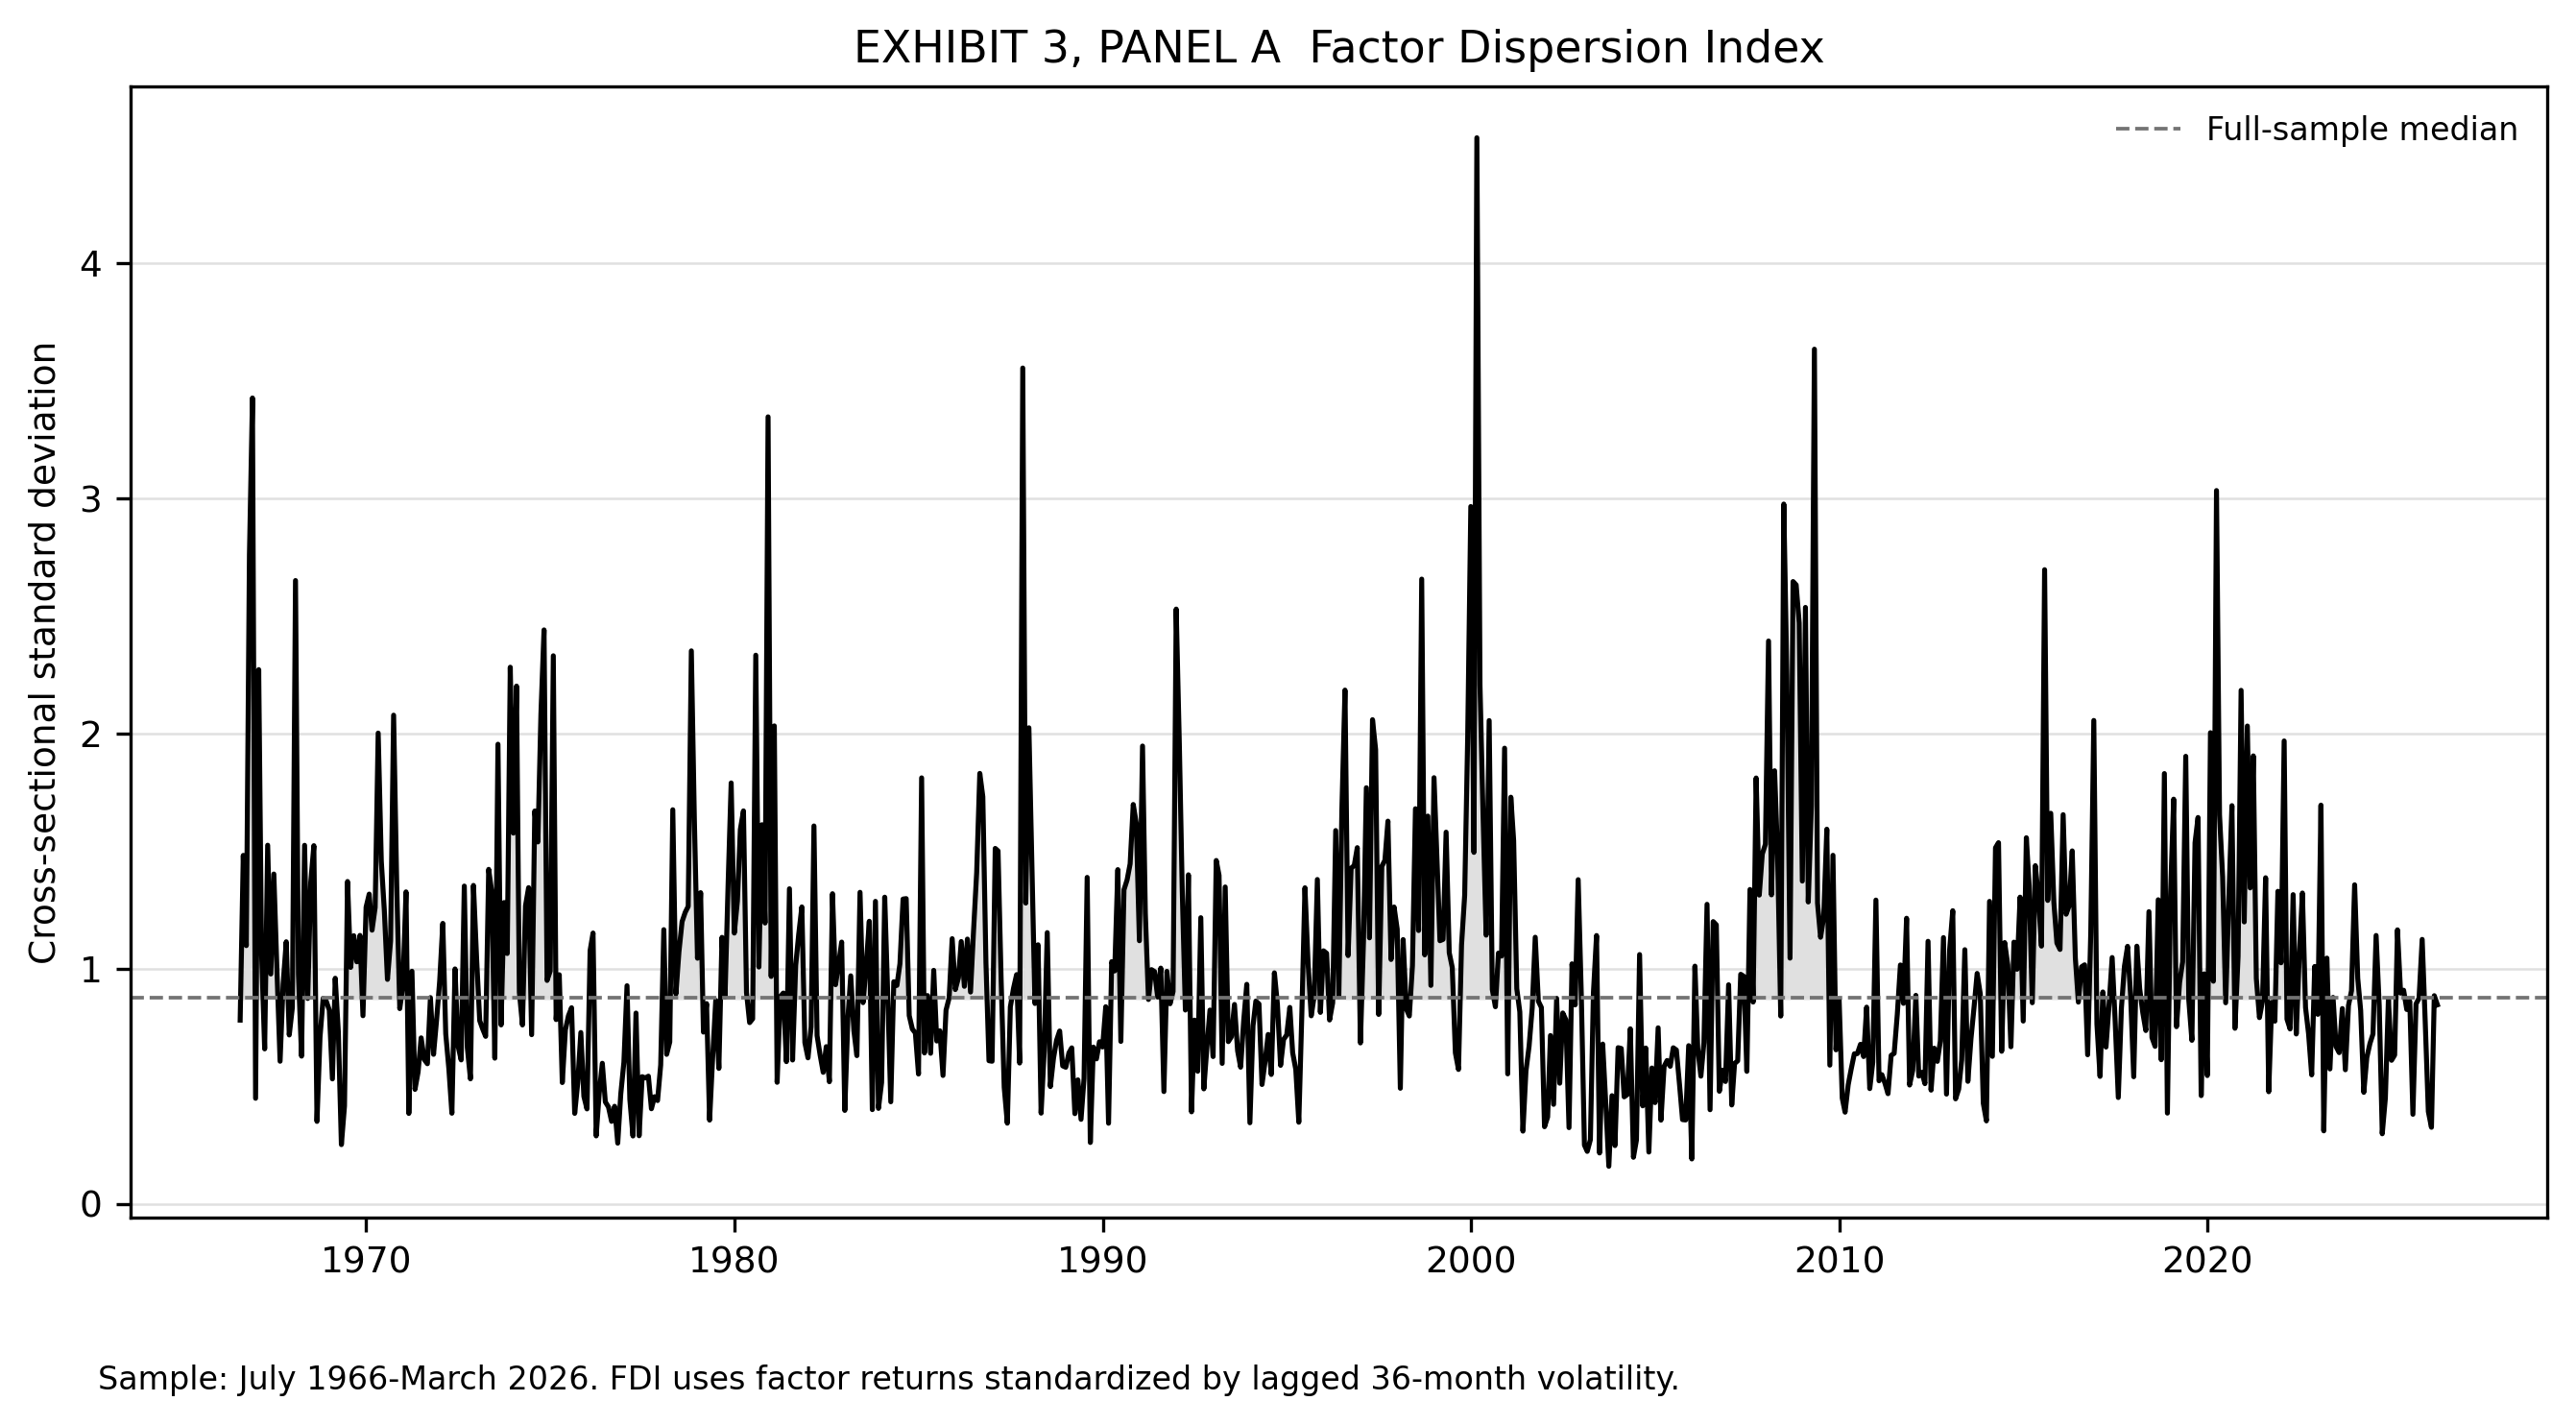

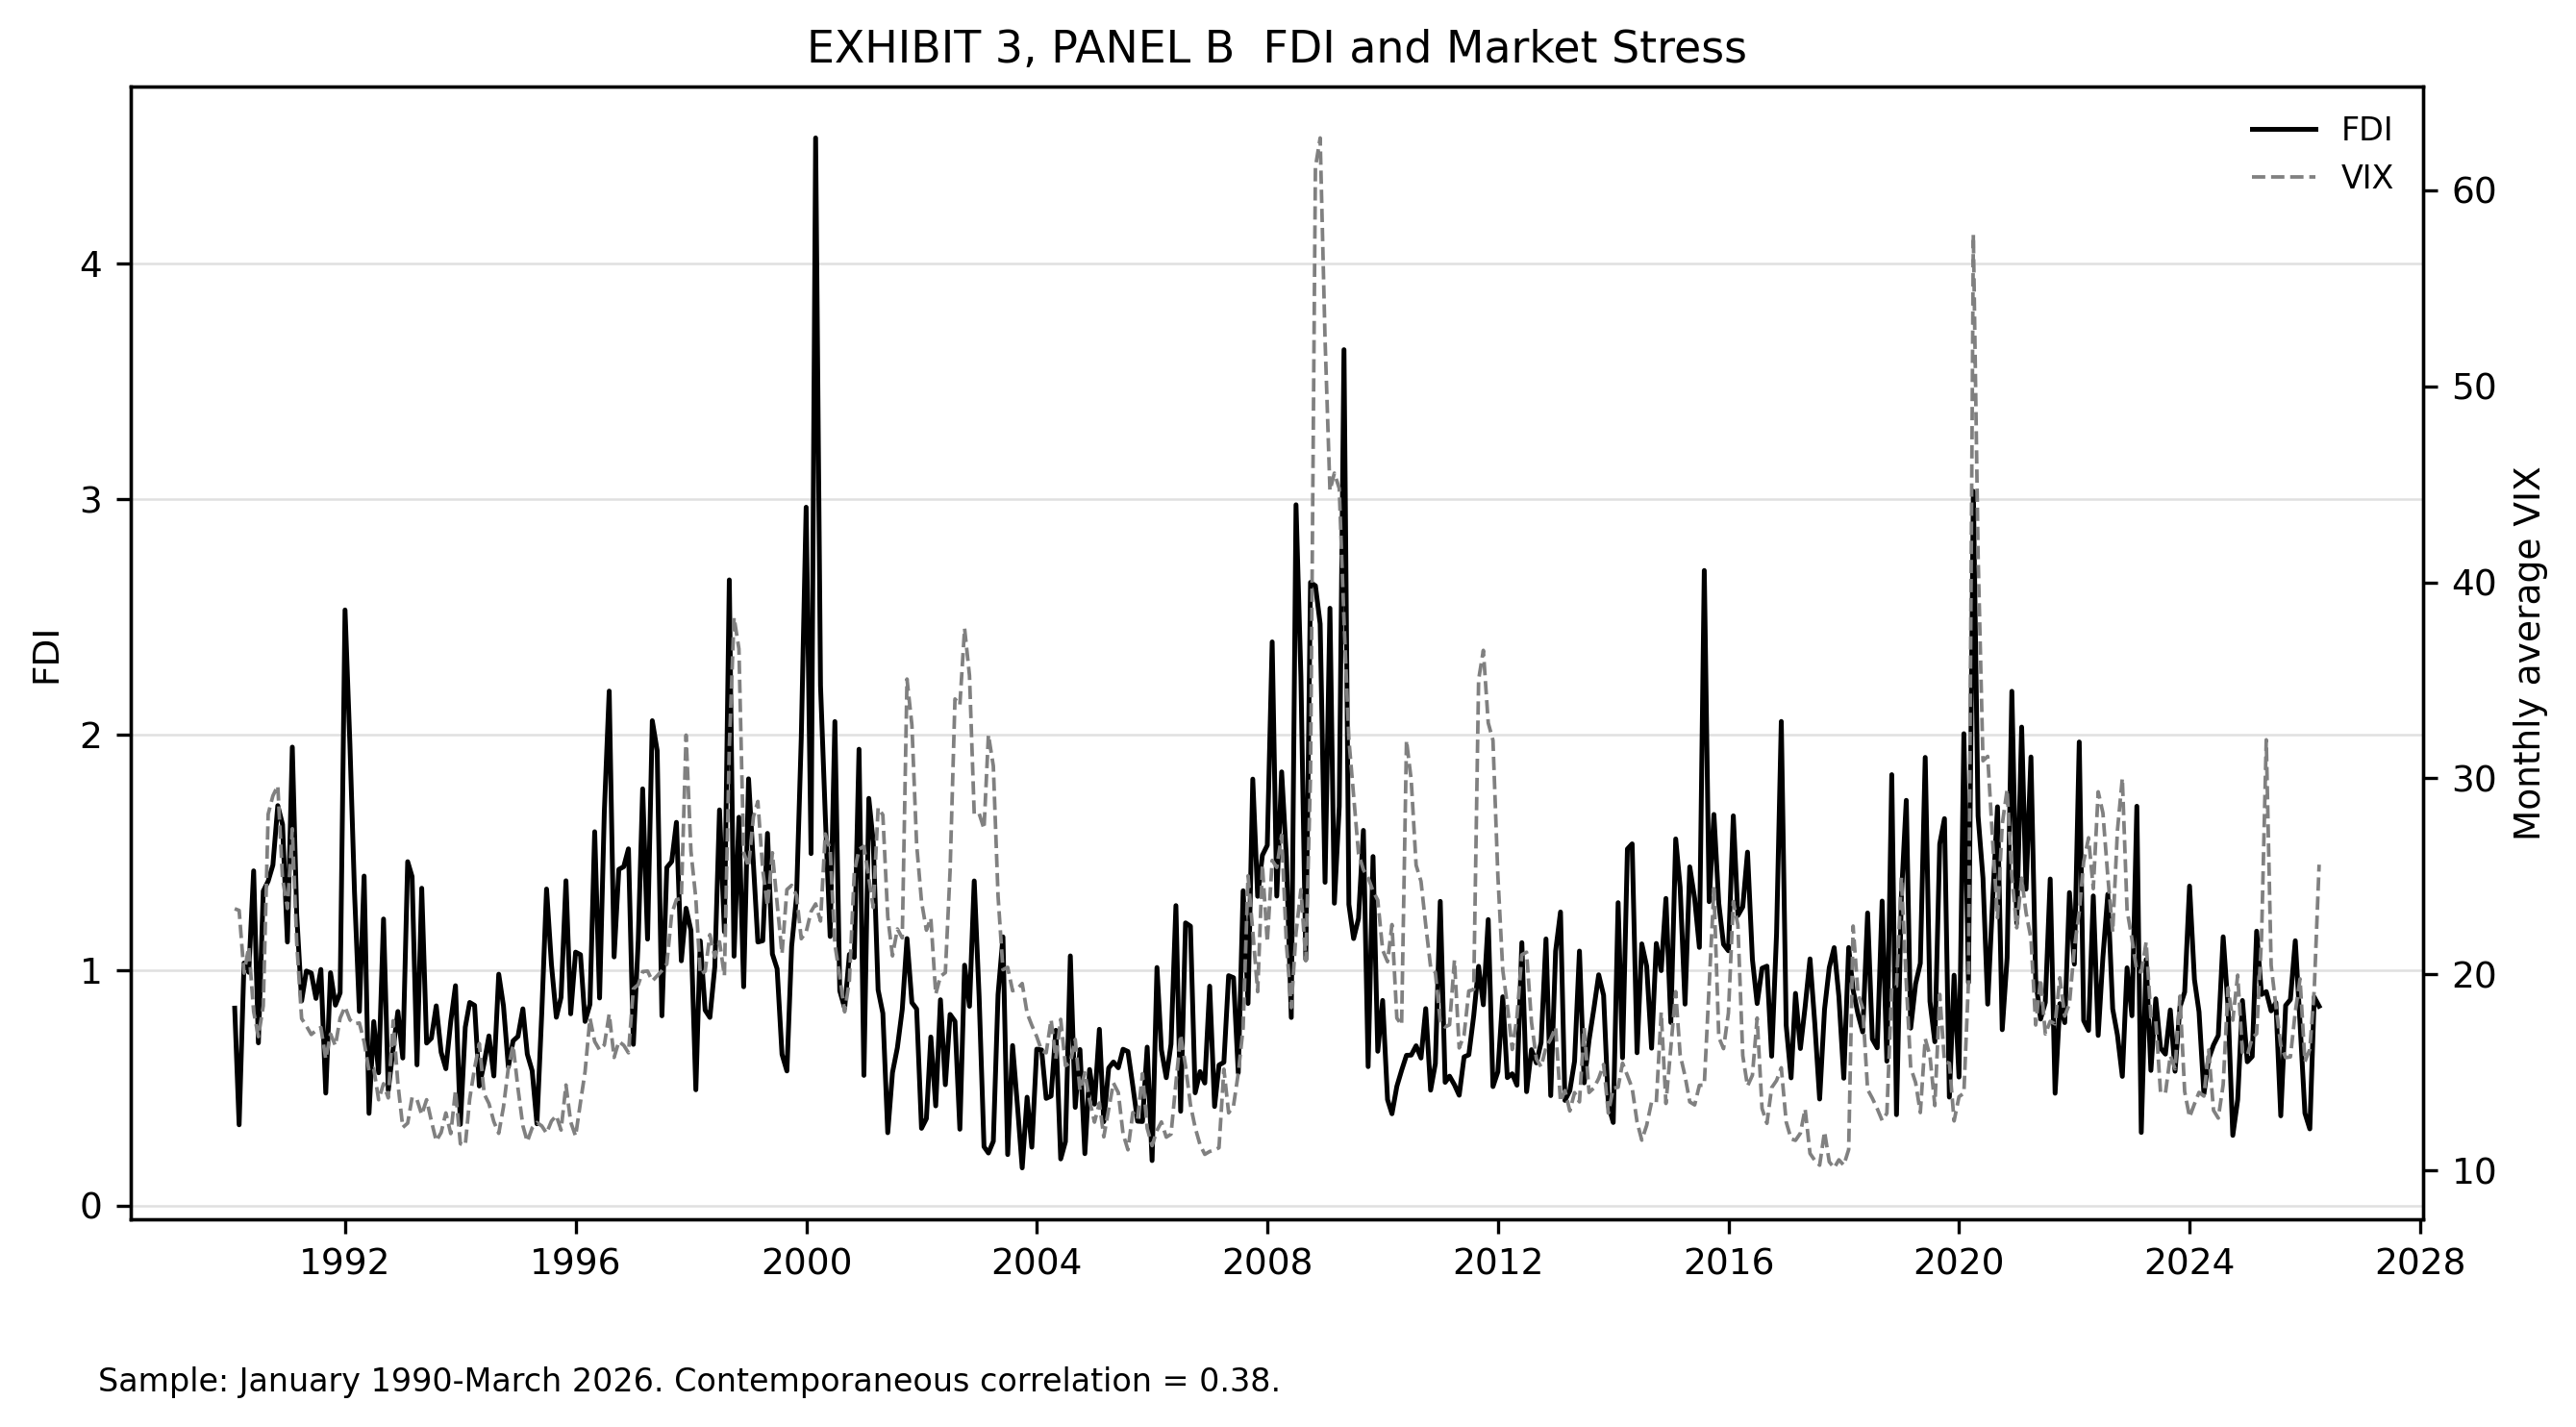

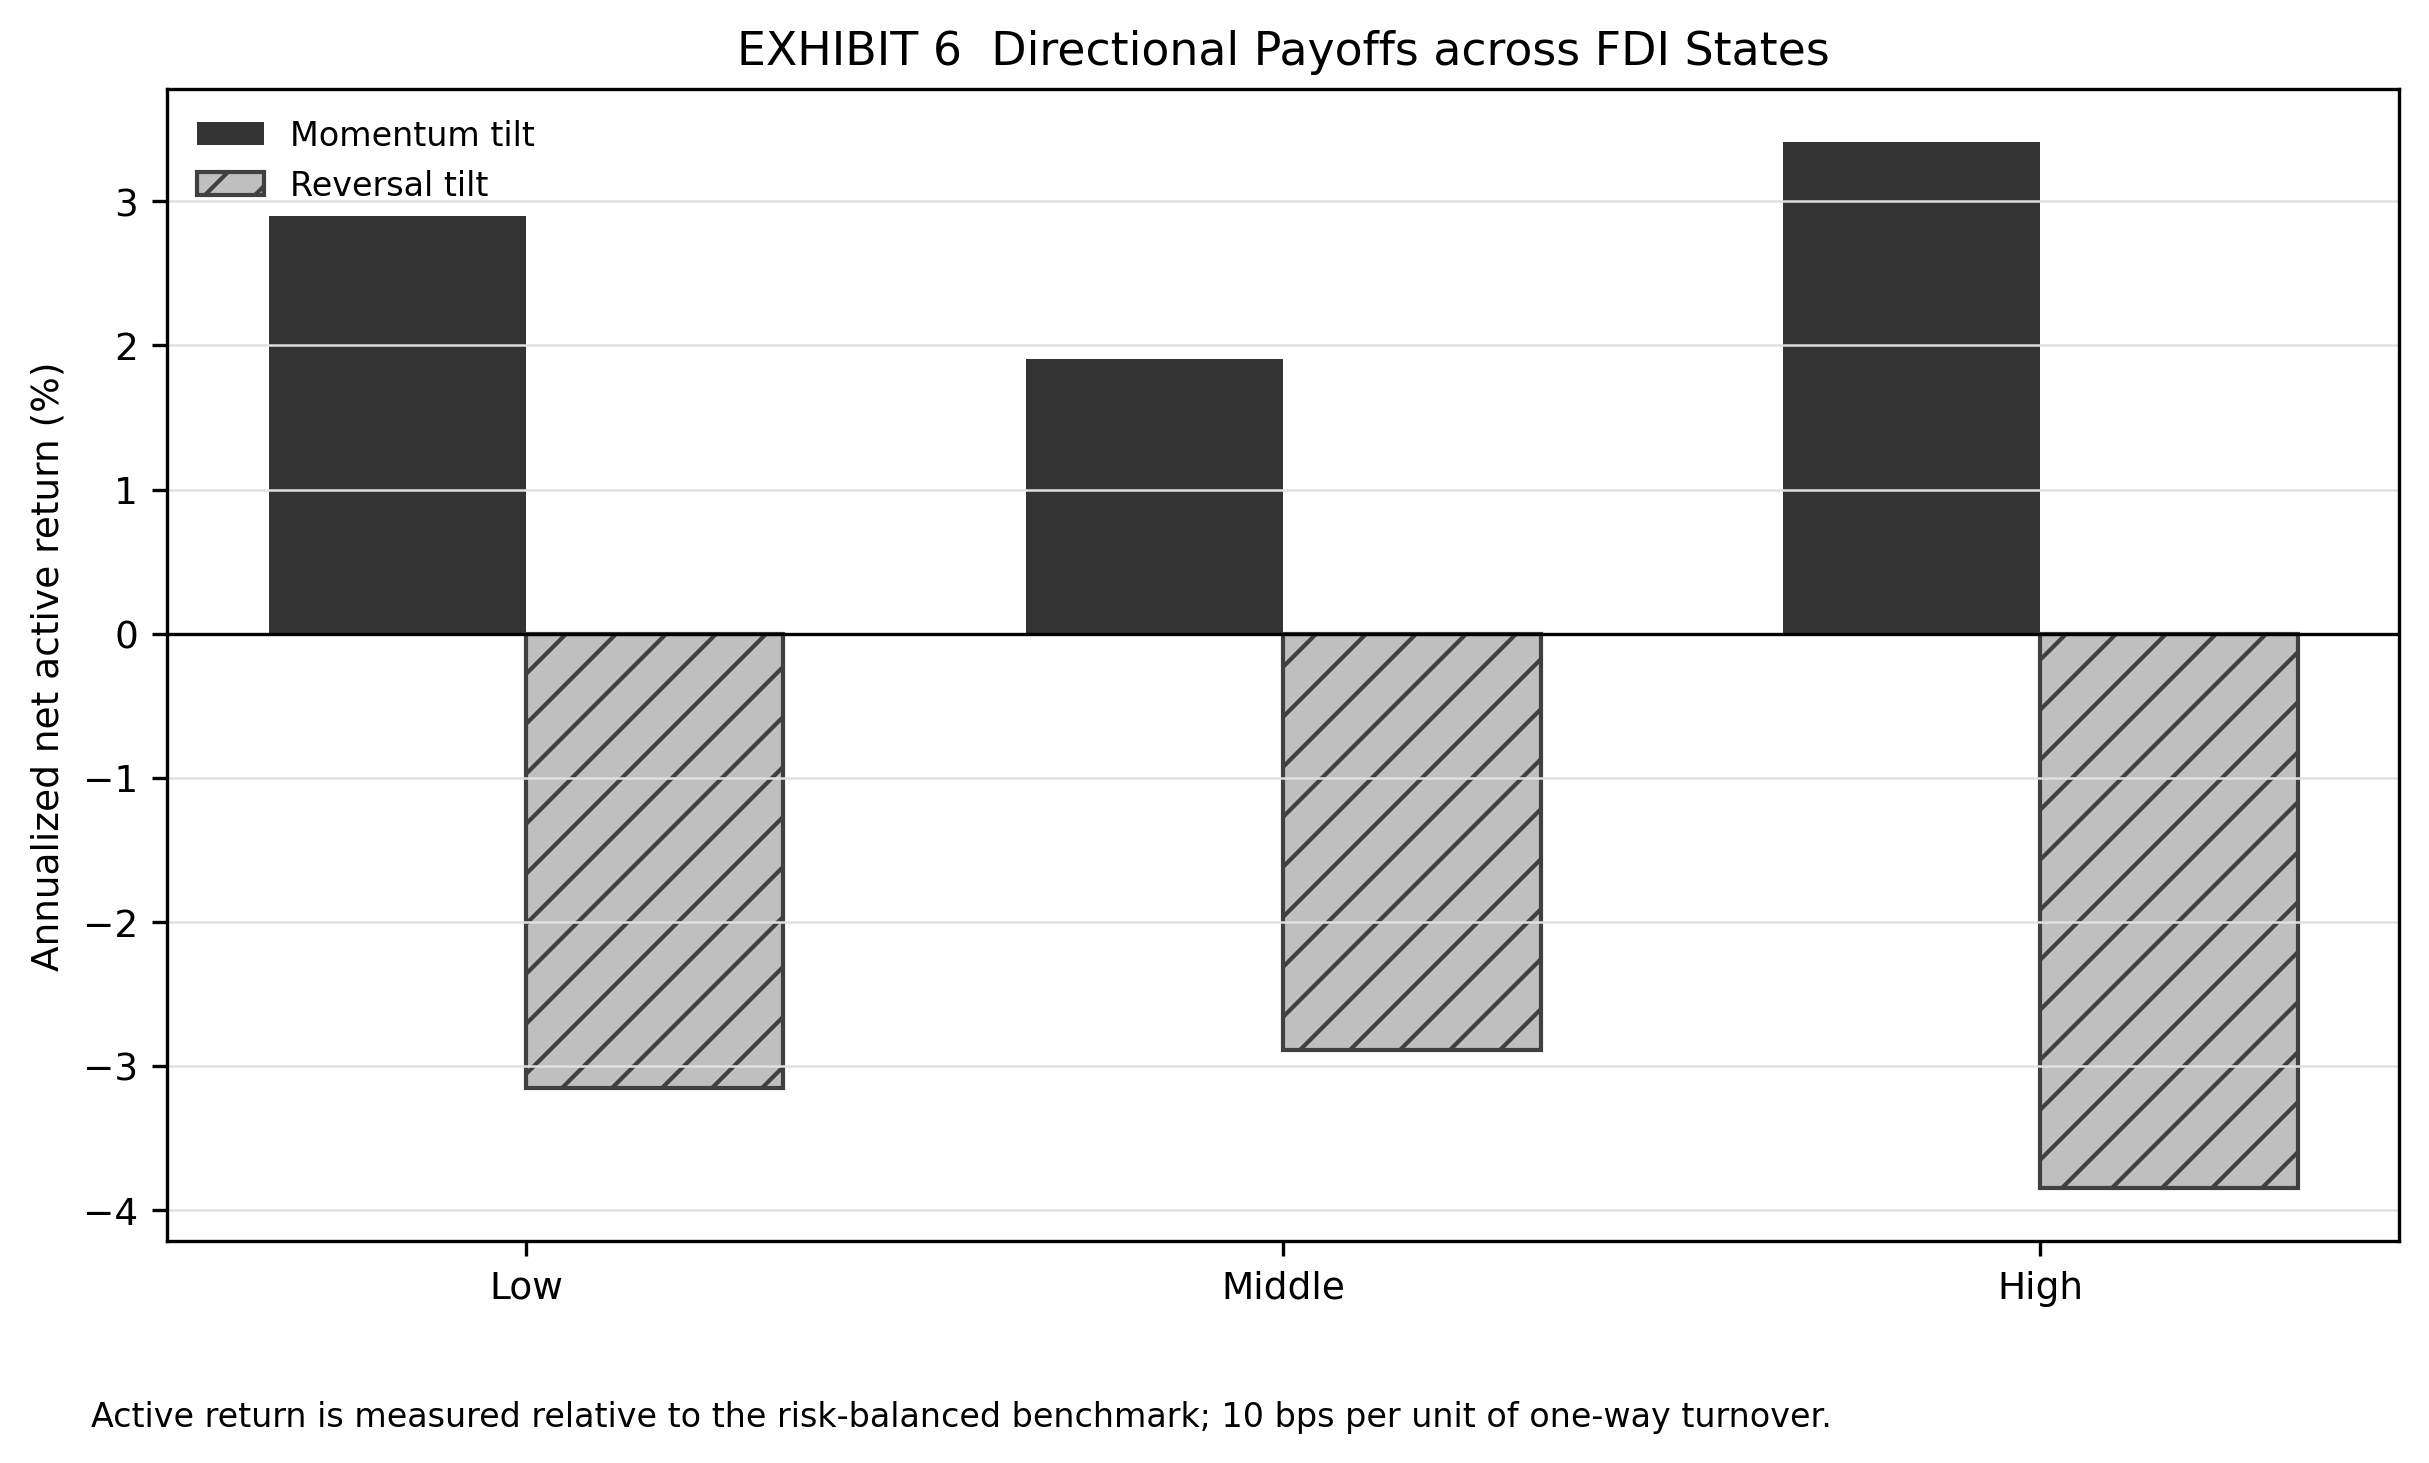

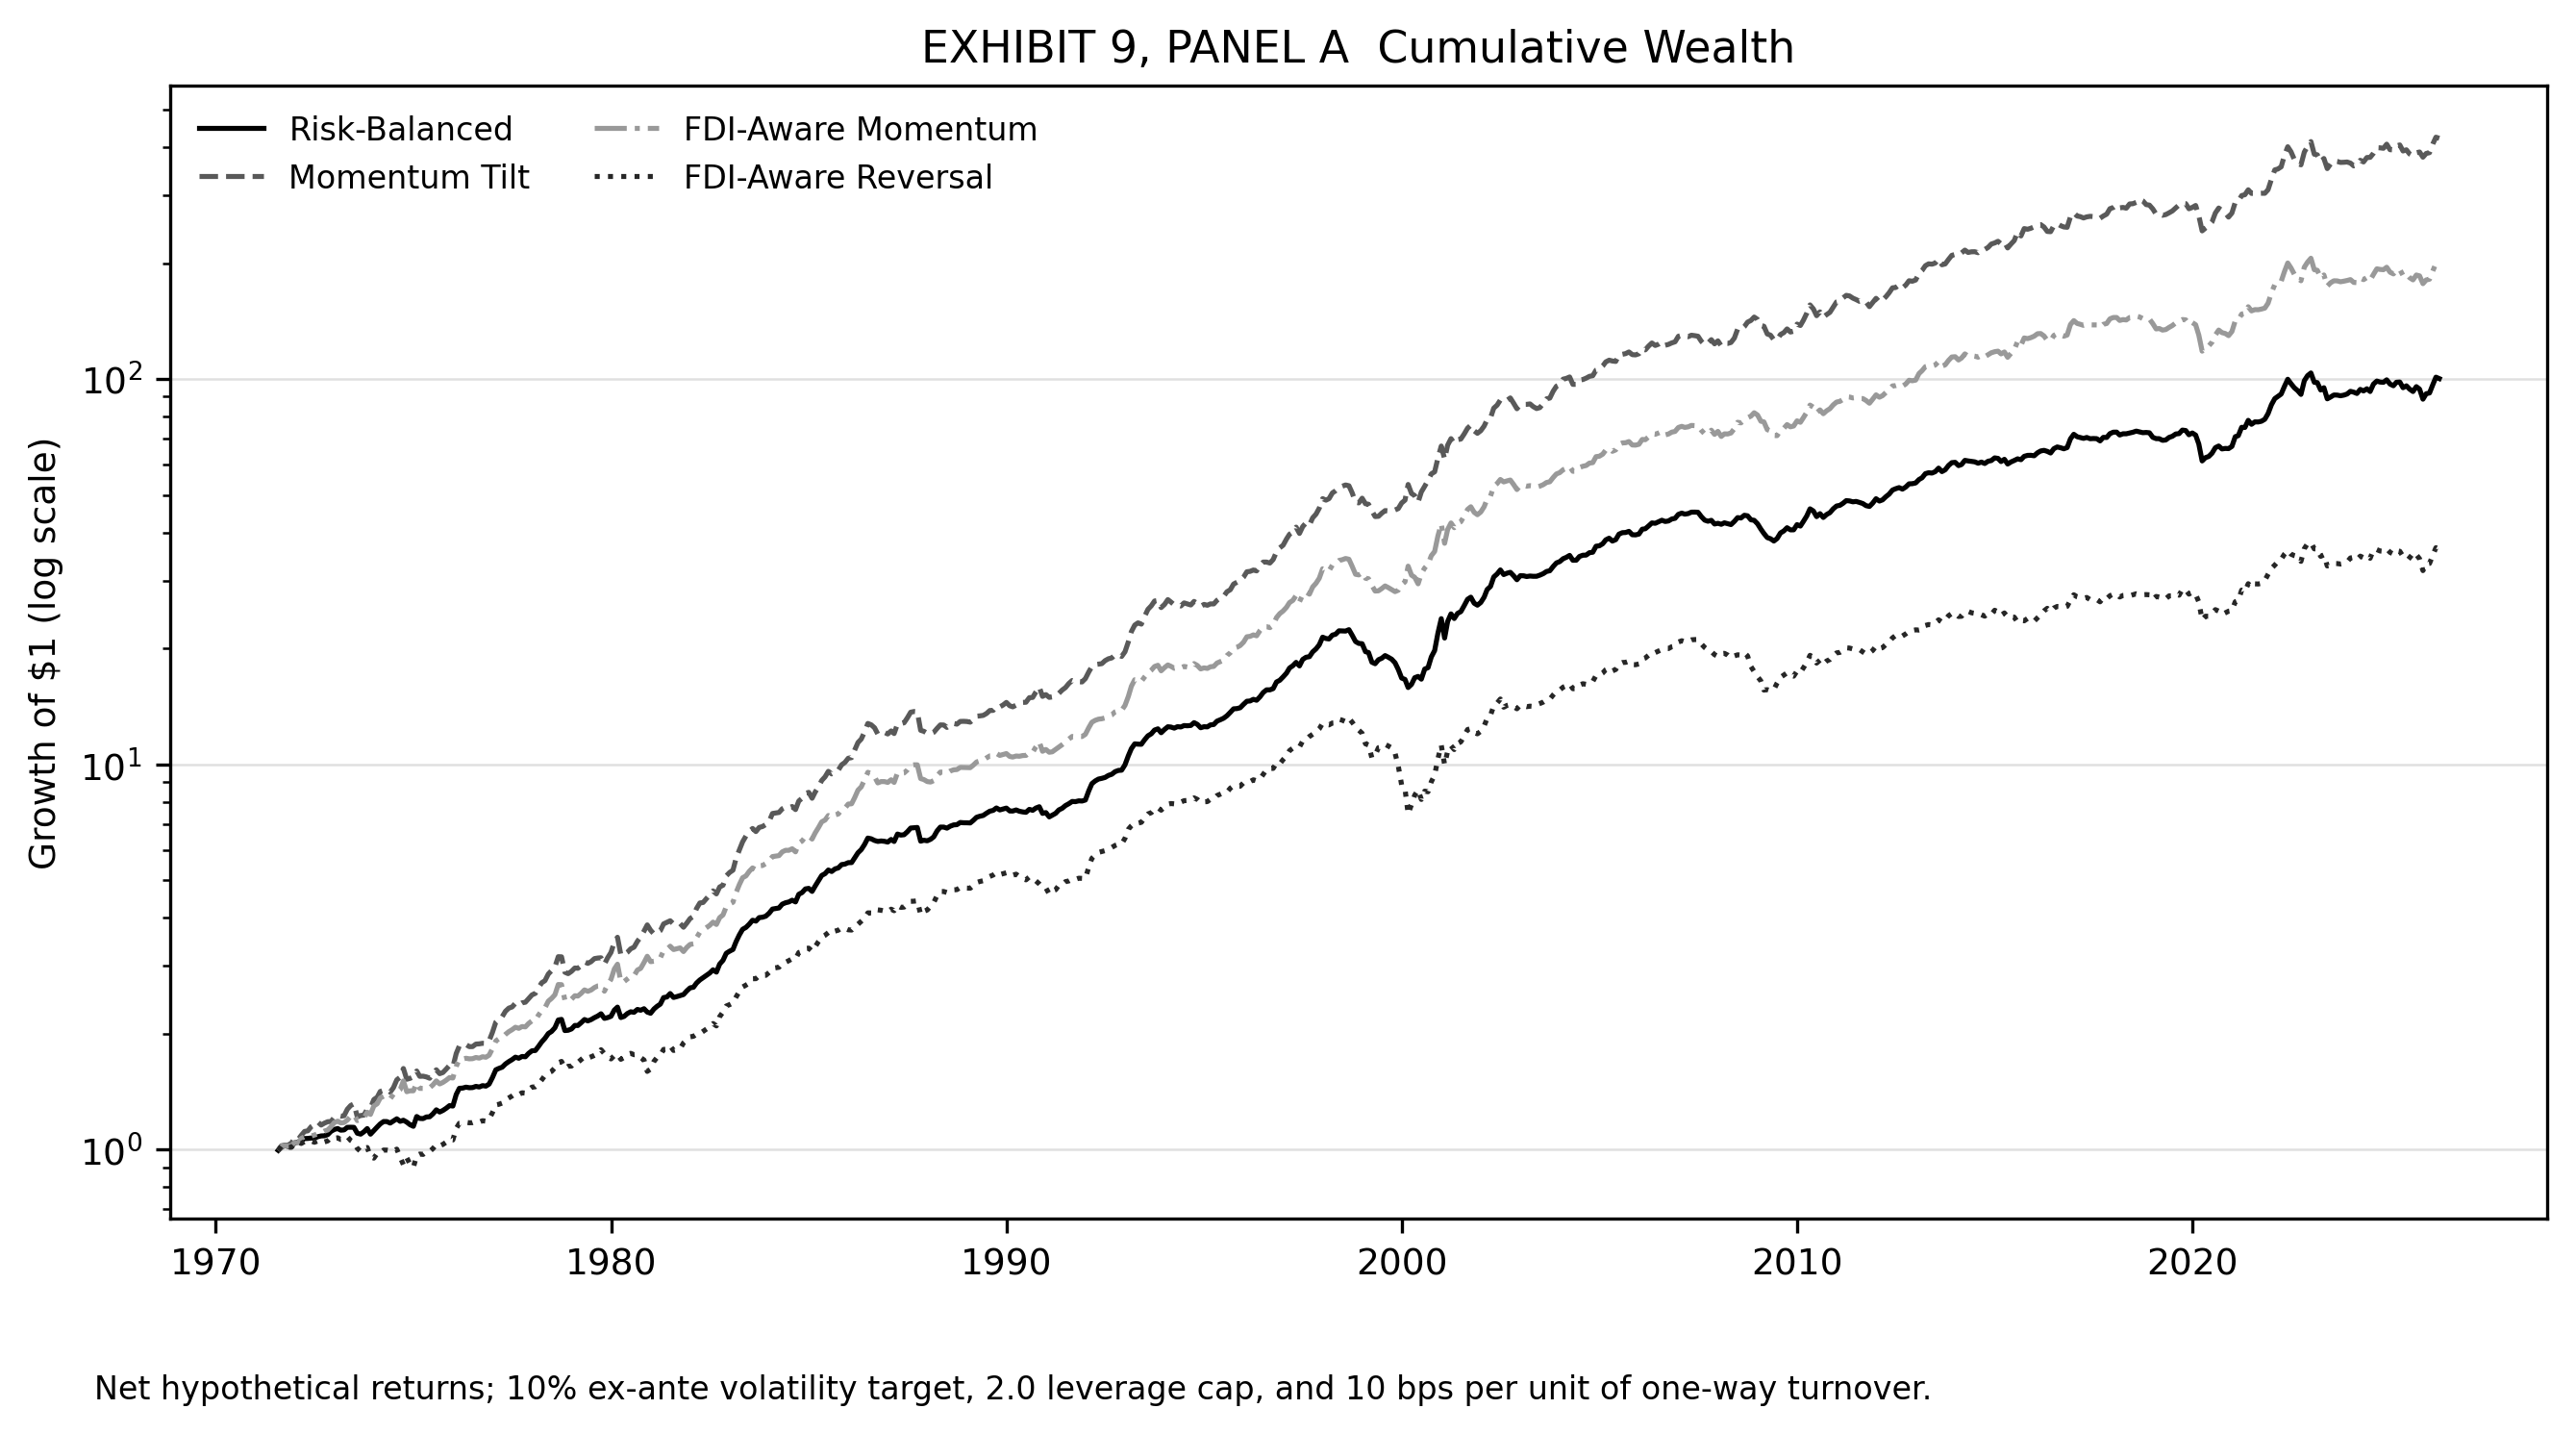

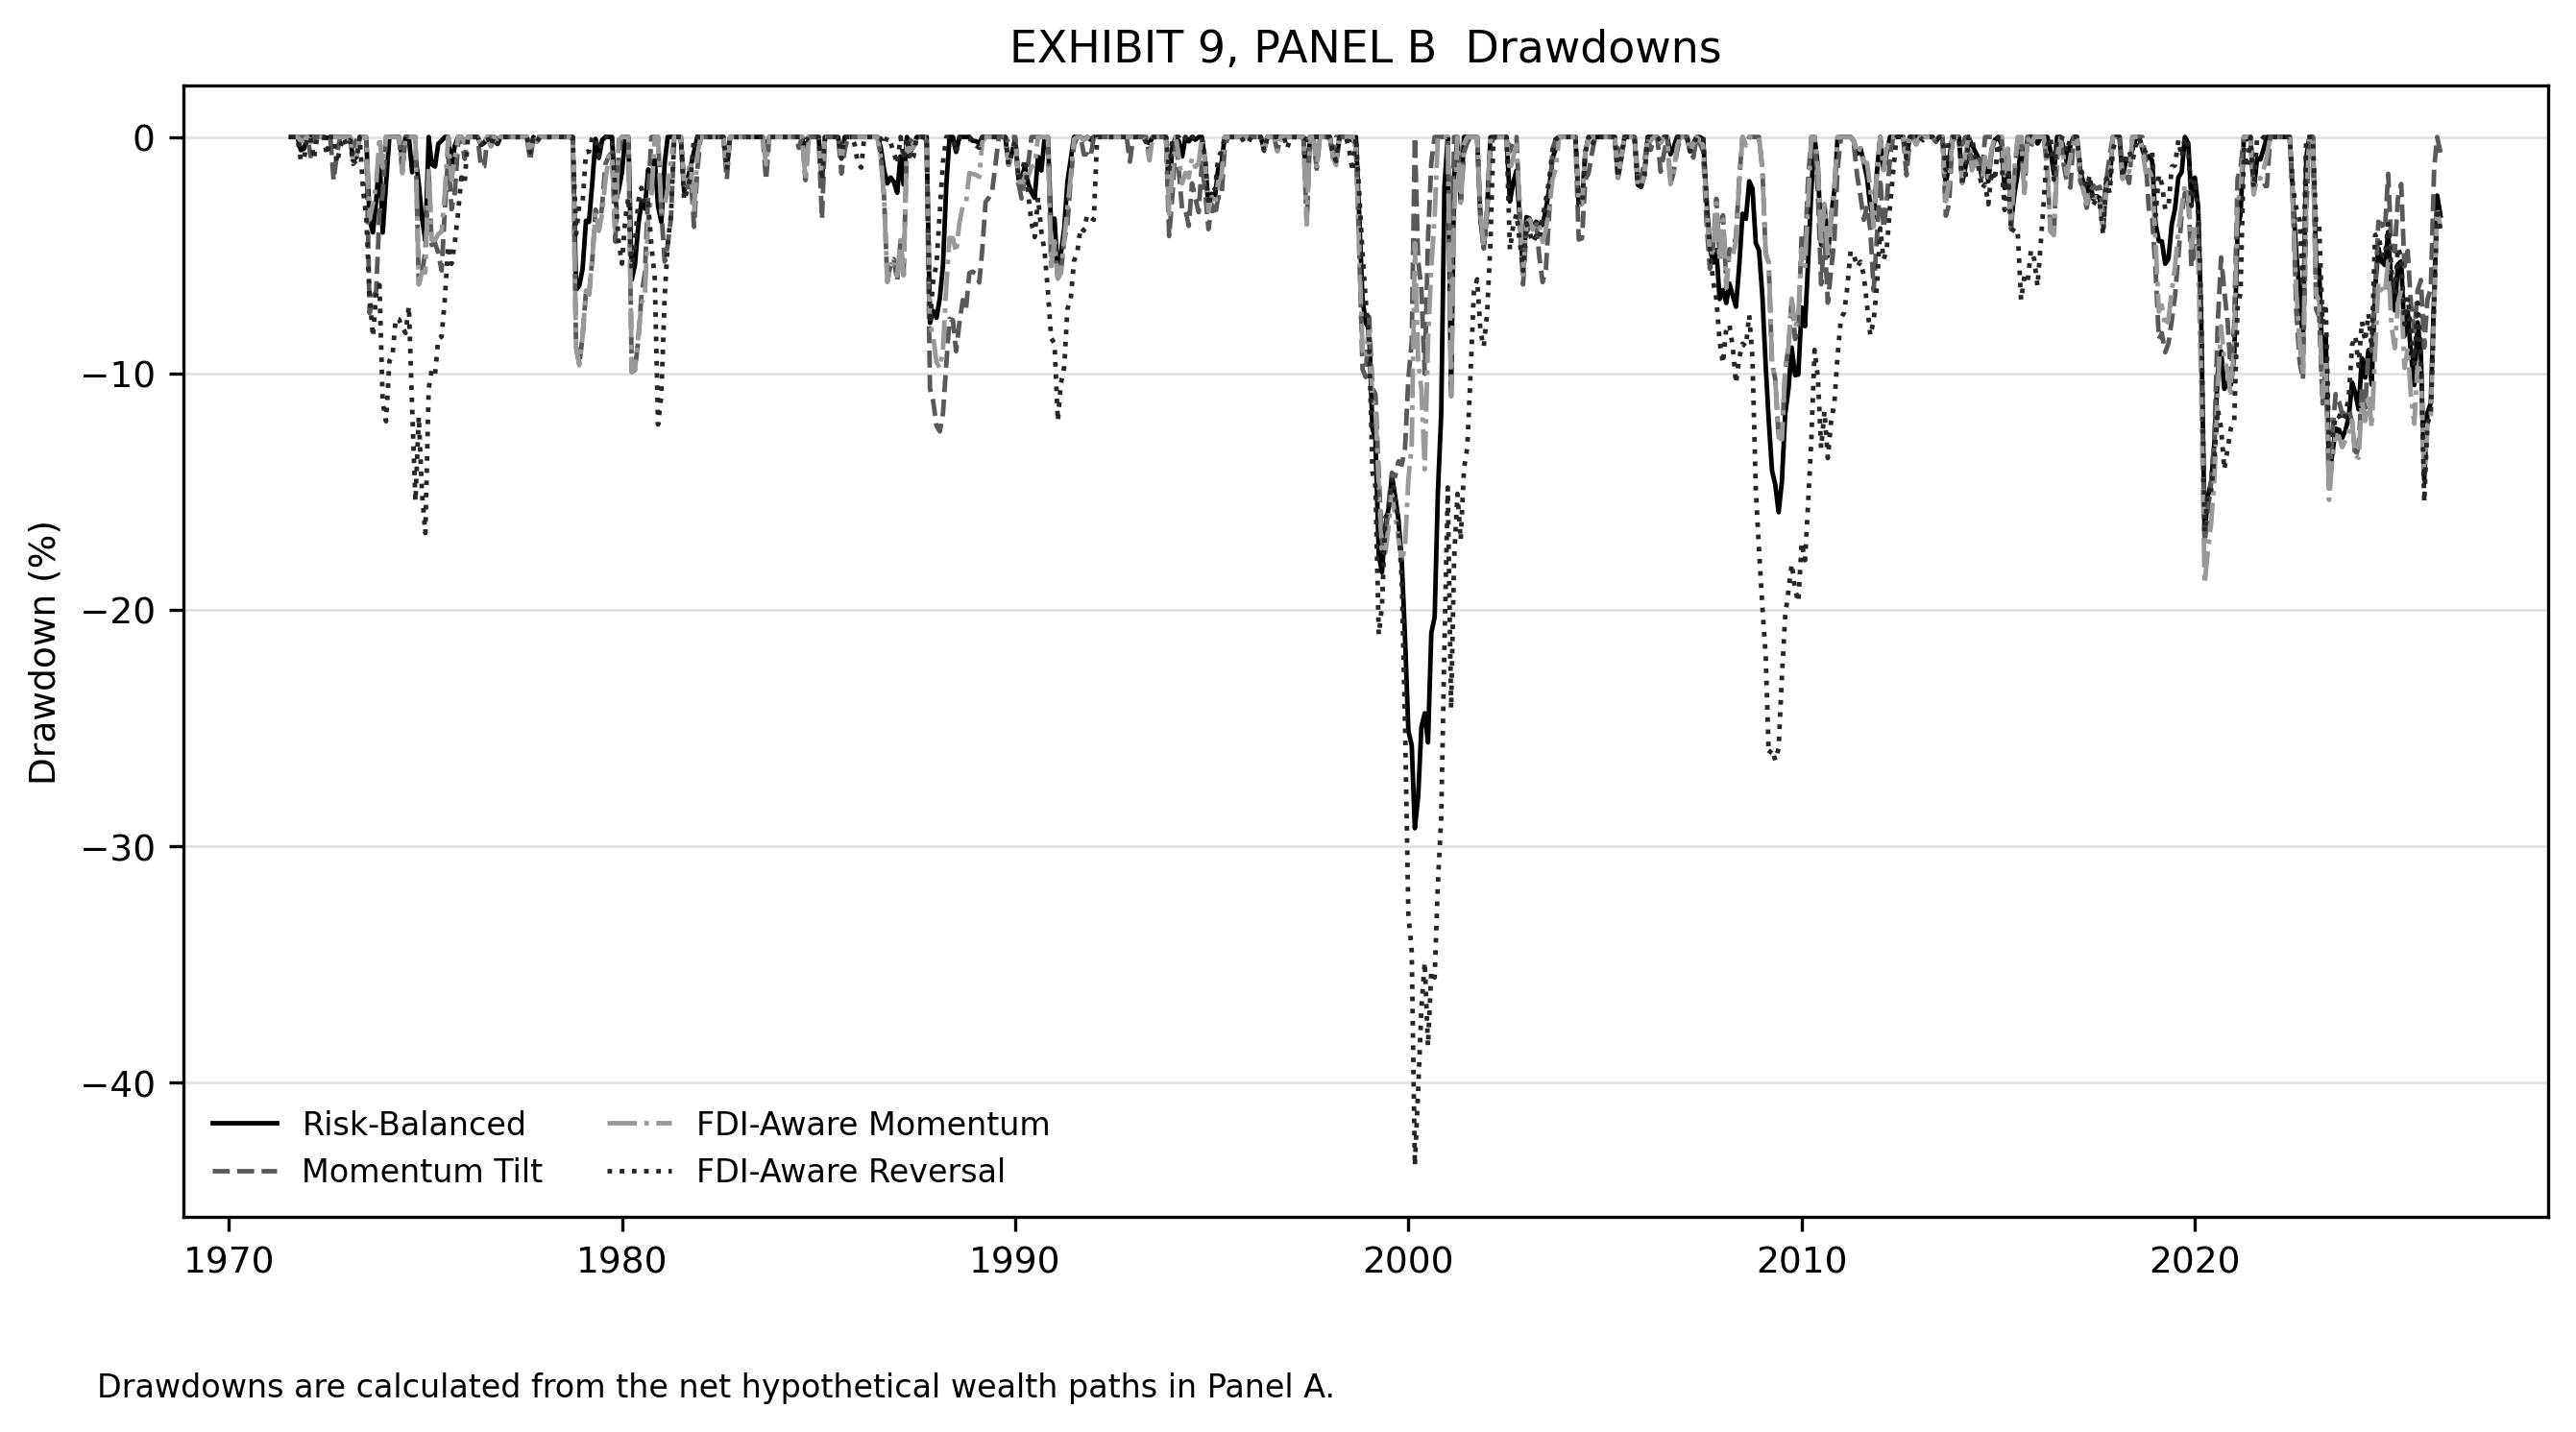

In [6]:
figure_paths = [
    OUTPUT_DIR / "figures" / "Exhibit_3_Panel_A_Factor_Dispersion_Index.png",
    OUTPUT_DIR / "figures" / "Exhibit_3_Panel_B_FDI_and_VIX.png",
    OUTPUT_DIR / "figures" / "Exhibit_6_Directional_Payoffs_by_FDI_State.png",
    OUTPUT_DIR / "figures" / "Exhibit_9_Panel_A_Cumulative_Wealth.png",
    OUTPUT_DIR / "figures" / "Exhibit_9_Panel_B_Drawdowns.png",
]
try:
    from IPython.display import Image, display
    for figure_path in figure_paths:
        display(Image(filename=str(figure_path)))
except ImportError:
    for figure_path in figure_paths:
        print(figure_path.resolve())


## Output inventory

The `fdi_notebook_outputs` folder contains all exhibit tables, factor inputs and signals, matched-sample raw-dispersion and active-TE predictive tests, both TE targeting strategies, gross/net series, weight paths, paired dependent-sample Sharpe intervals, BAB exclusions, figures and the JSON results summary. The input series represent gross research portfolios, not costs or returns from live tradable portfolios.

In [7]:
for file in sorted(OUTPUT_DIR.rglob("*")):
    if file.is_file():
        print(file.relative_to(OUTPUT_DIR))


exhibit_payload.json
factor_momentum_scores.csv
figures\Exhibit_3_Panel_A_Factor_Dispersion_Index.png
figures\Exhibit_3_Panel_B_FDI_and_VIX.png
figures\Exhibit_6_Directional_Payoffs_by_FDI_State.png
figures\Exhibit_9_Panel_A_Cumulative_Wealth.png
figures\Exhibit_9_Panel_B_Drawdowns.png
key_results.json
merged_factor_fdi_data.csv
standardized_factor_returns.csv
strategy_gross_returns.csv
strategy_net_returns.csv
strategy_turnover.csv
tables\Exhibit_10_Cost_Sensitivity.csv
tables\Exhibit_10_Excluding_BAB.csv
tables\Exhibit_10_Excluding_BAB_Gross.csv
tables\Exhibit_10_Robustness.csv
tables\Exhibit_10_Subperiods.csv
tables\Exhibit_1_Factor_Characteristics.csv
tables\Exhibit_2_FDI_Construction_Summary.csv
tables\Exhibit_2_Standardized_Return_Correlation.csv
tables\Exhibit_3_Time_Series_Data.csv
tables\Exhibit_4_Spread_Predictive_Tests.csv
tables\Exhibit_4_State_Opportunity.csv
tables\Exhibit_5_Incremental_Controls.csv
tables\Exhibit_5_Predictive_Regressions.csv
tables\Exhibit_5_Trailing_TE_